[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv (6392 rows, cols=['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords']...)
[data] train=5113 val=1279
Downloading: "https://download.pytorch.org/models/resnet101-63fe2227.pth" to /root/.cache/torch/hub/checkpoints/resnet101-63fe2227.pth


100%|██████████| 171M/171M [00:00<00:00, 212MB/s] 


epoch 01/5 loss=0.6227 val_mAUC=0.5650
epoch 02/5 loss=0.4985 val_mAUC=0.6806
epoch 03/5 loss=0.4620 val_mAUC=0.6975
epoch 04/5 loss=0.4472 val_mAUC=0.7020
epoch 05/5 loss=0.4388 val_mAUC=0.7049
[train] best val mAUC=0.7049 saved -> /kaggle/working/cipl_odir_best.pth


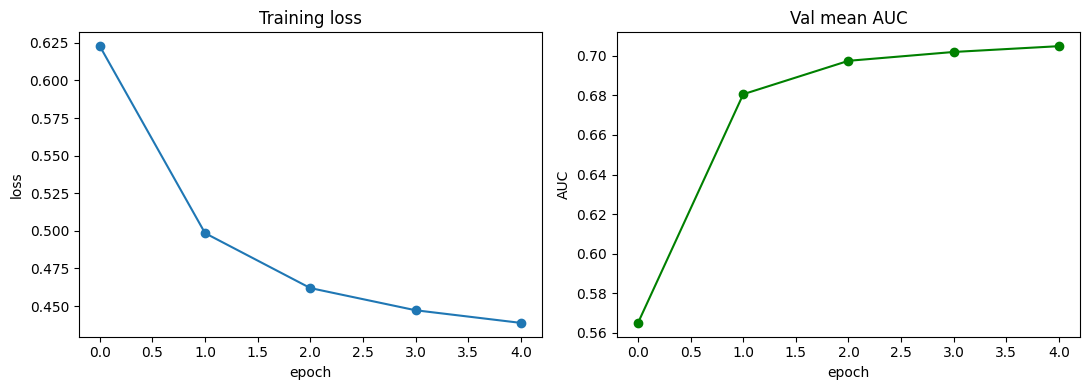


[eval] mean AUC = 0.7049
[eval] macro-F1 = 0.0000
[eval] subset-accuracy = 0.0000

              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       392
    Diabetes       0.00      0.00      0.00       446
    Glaucoma       0.00      0.00      0.00        84
    Cataract       0.00      0.00      0.00        82
         AMD       0.00      0.00      0.00        59
Hypertension       0.00      0.00      0.00        45
      Myopia       0.00      0.00      0.00        67
       Other       0.00      0.00      0.00       327

   micro avg       0.00      0.00      0.00      1502
   macro avg       0.00      0.00      0.00      1502
weighted avg       0.00      0.00      0.00      1502
 samples avg       0.00      0.00      0.00      1502



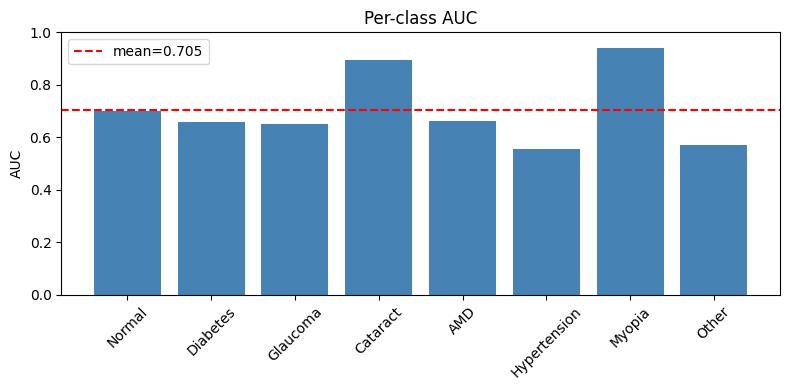

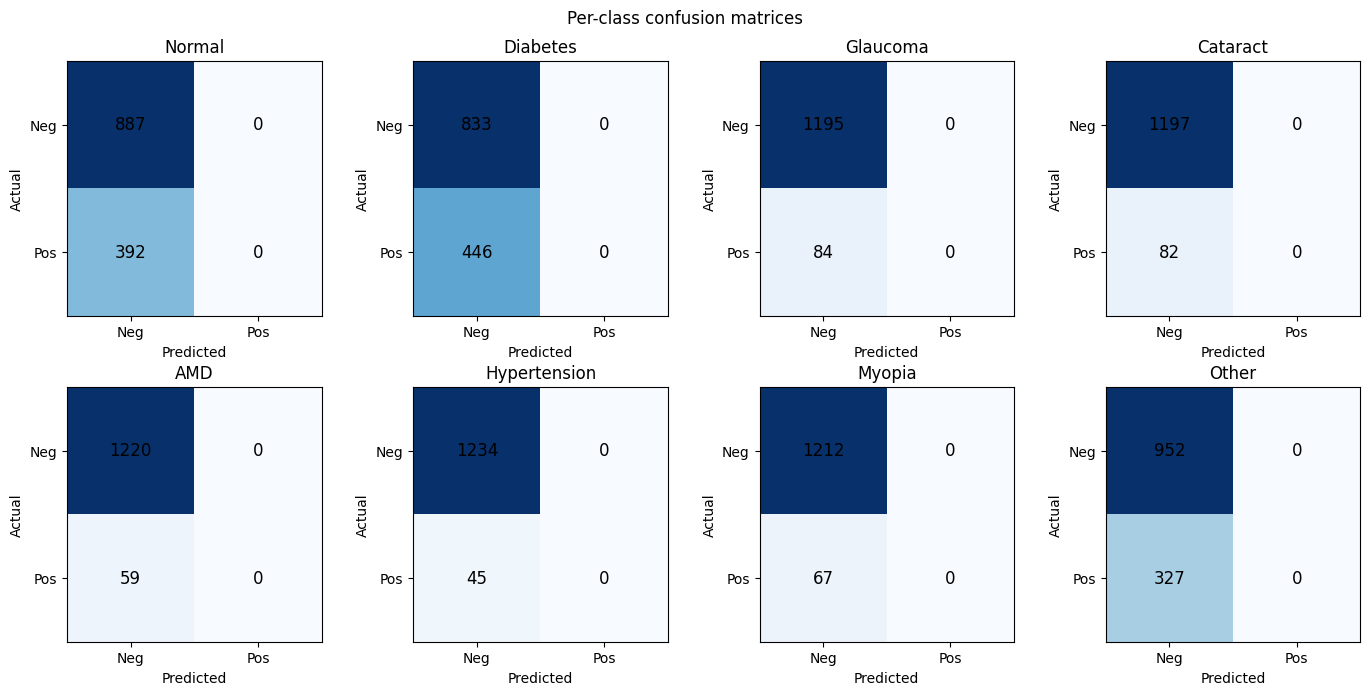


=== 3-OUTPUT DEMO ===
image: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images/3969_right.jpg
1) CLASSIFICATION: Normal
3) REPORT:
Findings: none above threshold.
Impression: within normal limits.


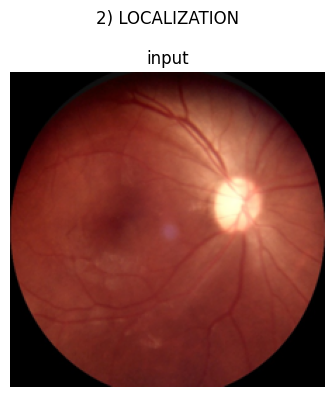


[done] plots saved in /kaggle/working: curves.png auc_bar.png confusion.png demo.png


In [1]:
"""
cipl_odir_full.py — ONE runnable pipeline for the sir's brief
================================================================
Does all THREE things, plus training + evaluation + plots + matrices:
    TASK 1 classification -> multi-label (8 ODIR classes)
    TASK 2 localization -> colored heatmap mask from prototype similarity maps
    TASK 3 text report -> short template summary (NOT in the paper; added here)
    Extras you asked for:
        - correct Kaggle paths, auto-detected + LOUD failure (kills the 0.50 black-image bug)
        - training loop with saved best checkpoint
        - plots: loss curve, mean-AUC curve, per-class AUC bar
        - matrices: 8 per-class confusion matrices + classification report
        - a 3-output demo figure on one validation image
DATASET (default): kaggle andrewmvd/ocular-disease-recognition-odir5k
    /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images/*.jpg
    /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv (cols N,D,G,C,A,H,M,O + filename)
TWO WAYS TO RUN
    A) TRAIN = True -> trains a few epochs, then evaluates + plots everything (gives curves)
    B) TRAIN = False -> loads CKPT (your ~0.79 baseline) and just evaluates + plots
Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
All present on Kaggle.
"""
import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)
try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")
# ======================================================================
# 0. CONFIG — edit these
# ======================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR = "/kaggle/working"
CKPT = os.path.join(OUT_DIR, "cipl_odir_best.pth")
CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS = ["N", "D", "G", "C", "A", "H", "M", "O"] # one-hot cols in full_df.csv
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX = 0
IMG_SIZE = 224
BATCH = 32
EPOCHS = 5 # a few epochs; raise for better AUC (takes longer)
LR = 1e-4
THRESHOLD = 0.5
PROTOS = 10 # prototypes per class
SEED = 42
TRAIN = True # False -> load CKPT and only evaluate + plot
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")
# ======================================================================
# 1. DATA — auto-detect paths/labels, FAIL LOUDLY if wrong
# ======================================================================
def find_image_dir(root):
    for c in ["preprocessed_images",
              "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images",
              "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(
        f"No image folder found under {root}.\n"
        f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")
def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No label CSV found under {root}. Contents: {os.listdir(root)}")
def build_dataframe():
    img_dir = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path} ({len(df)} rows, cols={list(df.columns)[:6]}...)")
    # -- labels: prefer the 8 one-hot columns; else parse a 'target' list column
    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32)
                           for t in df["target"]])
    else:
        raise KeyError(f"Cannot find labels. Need columns {LABEL_COLS} or 'target'. "
                       f"Got: {list(df.columns)}")
    # -- filename column
    if "filename" in df.columns:
        fnames = df["filename"].astype(str).values
    else:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")
    # -- verify files exist; drop missing LOUDLY (do NOT silently substitute)
    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    n_missing = len(keep) - int(np.sum(keep))
    if n_missing == len(keep):
        raise FileNotFoundError(f"NONE of the {len(keep)} images exist in {img_dir}. "
                                f"Sample expected: {os.path.join(img_dir, fnames[0])}")
    if n_missing:
        print(f"[data] WARNING: {n_missing}/{len(keep)} image files missing -> dropped")
    fnames, labels = fnames[keep], labels[np.array(keep)]
    return img_dir, fnames, labels
class ODIRDataset(Dataset):
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])
    def __len__(self):
        return len(self.fnames)
    def __getitem__(self, i):
        # NO bare except here — a bad path must crash, not become a black image
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])
def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)} val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True, num_workers=2),
            DataLoader(val_ds, BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])
# ======================================================================
# 2. MODEL — cosine-prototype net; returns (logits, per-class sim maps)
# ======================================================================
class PrototypeNet(nn.Module):
    """
    features -> [B,2048,h,w] -> 1x1 conv head -> [B,256,h,w]
    prototypes P: [C*M, 256]; cosine sim at each location -> [B, C*M, h, w]
    per-class map = max over that class's M prototypes -> [B, C, h, w] (localization)
    class logit = maxpool sim -> [B, C*M] -> Linear -> [B, C] (classification)
    prototype n belongs to class (n // M)
    """
    def __init__(self, num_classes=NUM_CLASSES, m=PROTOS, feat_dim=256, pretrained=True):
        super().__init__()
        w = "IMAGENET1K_V1" if pretrained else None
        try:
            backbone = torchvision.models.resnet101(weights=w)
        except Exception: # no internet on Kaggle -> random init
            backbone = torchvision.models.resnet101(weights=None)
        self.features = nn.Sequential(*list(backbone.children())[:-2])
        self.add_on = nn.Sequential(
            nn.Conv2d(2048, feat_dim, 1), nn.ReLU(),
            nn.Conv2d(feat_dim, feat_dim, 1), nn.Sigmoid())
        self.C, self.M, self.N = num_classes, m, num_classes * m
        self.prototypes = nn.Parameter(torch.rand(self.N, feat_dim))
        self.classifier = nn.Linear(self.N, num_classes)
    def forward(self, x):
        f = self.add_on(self.features(x)) # [B,D,h,w]
        B, D, h, w = f.shape
        fn = F.normalize(f, dim=1)
        pn = F.normalize(self.prototypes, dim=1) # [N,D]
        sim = torch.einsum("bdhw,nd->bnhw", fn, pn) # [B,N,h,w] cosine
        proto_scores = F.adaptive_max_pool2d(sim, 1).flatten(1) # [B,N]
        logits = self.classifier(proto_scores) # [B,C]
        sim_cls = sim.view(B, self.C, self.M, h, w).max(2).values # [B,C,h,w]
        return logits, sim_cls, proto_scores
# ======================================================================
# 3. LOSS — BCE + light clustering/separation (simplified CIPL)
# (paper also adds cross-attention + 2 alignment losses; omitted for clarity)
# ======================================================================
bce = nn.BCEWithLogitsLoss()
def cipl_lite_loss(logits, proto_scores, y, w_clst=0.1, w_sep=0.1):
    B = y.shape[0]
    best = proto_scores.view(B, NUM_CLASSES, PROTOS).max(2).values # [B,C] best proto sim/class
    pos, neg = y, 1.0 - y
    clst = ((1 - best) * pos).sum() / (pos.sum() + 1e-8) # positives -> high sim
    sep = (F.relu(best) * neg).sum() / (neg.sum() + 1e-8) # negatives -> low sim
    return bce(logits, y) + w_clst * clst + w_sep * sep
# ======================================================================
# 4. TRAIN
# ======================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy())
        Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)
def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        if len(np.unique(y_true[:, c])) < 2:
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs
def train(model, train_loader, val_loader):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"loss": [], "auc": []}
    best = -1
    for ep in range(1, EPOCHS + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, ps = model(x)
            loss = cipl_lite_loss(logits, ps, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        epoch_loss = running / len(train_loader.dataset)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(epoch_loss); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{EPOCHS} loss={epoch_loss:.4f} val_mAUC={auc:.4f}")
        if auc > best:
            best = auc; torch.save(model.state_dict(), CKPT)
    print(f"[train] best val mAUC={best:.4f} saved -> {CKPT}")
    return hist
# ======================================================================
# 5. PLOTS + MATRICES
# ======================================================================
def plot_curves(hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUC")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=120); plt.show()
def plot_auc_bar(aucs):
    plt.figure(figsize=(8, 4))
    vals = [0 if np.isnan(a) else a for a in aucs]
    plt.bar(CLASS_NAMES, vals, color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--",
                label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title("Per-class AUC")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar.png", dpi=120); plt.show()
def plot_confusion(y_true, y_pred):
    mcm = multilabel_confusion_matrix(y_true, y_pred) # [C,2,2]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]
        ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center",
                        color="black", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle("Per-class confusion matrices"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion.png", dpi=120); plt.show()
def evaluate(model, val_loader):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > THRESHOLD).astype(int)
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval] mean AUC = {auc:.4f}")
    print(f"[eval] macro-F1 = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval] subset-accuracy = {accuracy_score(ytrue, ypred):.4f}\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs)
    plot_confusion(ytrue, ypred)
# ======================================================================
# 6. THREE-OUTPUT DEMO on one validation image
# ======================================================================
def make_overlay(pil_img, class_map, size=IMG_SIZE):
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)
def peak_region(class_map):
    m = class_map.detach().cpu().numpy()
    y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left" if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"
def make_report(findings, sim_cls, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f" - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): "
                     f"activation in the {peak_region(sim_cls[0, c])}.")
    names = ", ".join(CLASS_NAMES[c] for c in findings)
    lines.append(f"\nImpression: consistent with {names}. Correlate clinically.")
    return "\n".join(lines)
_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
def demo(model, img_dir, val_fnames):
    path = os.path.join(img_dir, val_fnames[0])
    pil = Image.open(path).convert("RGB")
    x = _demo_tf(pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, sim_cls, _ = model(x)
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES) if probs[c] > THRESHOLD and c != NORMAL_IDX]
    print("\n=== 3-OUTPUT DEMO ===")
    print("image:", path)
    print("1) CLASSIFICATION:",
          ", ".join(CLASS_NAMES[c] for c in findings) if findings else "Normal")
    print("3) REPORT:\n" + make_report(findings, sim_cls, probs))
    n = 1 + len(findings)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1: axes = [axes]
    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("input")
    axes[0].axis("off")
    for k, c in enumerate(findings, 1):
        axes[k].imshow(make_overlay(pil, sim_cls[0, c]))
        axes[k].set_title(f"{CLASS_NAMES[c]} ({probs[c]:.2f})"); axes[k].axis("off")
    plt.suptitle("2) LOCALIZATION"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo.png", dpi=120); plt.show()
# ======================================================================
# 7. RUN
# ======================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, _ = make_loaders()
    model = PrototypeNet().to(DEVICE)
    if TRAIN:
        hist = train(model, train_loader, val_loader)
        plot_curves(hist)
        model.load_state_dict(torch.load(CKPT, map_location=DEVICE)) # reload best
    elif os.path.isfile(CKPT):
        state = torch.load(CKPT, map_location=DEVICE)
        model.load_state_dict(state.get("state_dict", state), strict=False)
        print(f"[model] loaded {CKPT}")
    else:
        print("[model] WARNING: TRAIN=False and no checkpoint -> results meaningless.")
    evaluate(model, val_loader)
    demo(model, img_dir, val_fnames)
    print(f"\n[done] plots saved in {OUT_DIR}: curves.png auc_bar.png confusion.png demo.png")
if __name__ == "__main__":
    main()

[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv  (6392 rows, cols=['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords']...)
[data] train=5113  val=1279
[train] pos_weight: [ 2.   2.  15.3 15.  18.7 31.4 20.4  3.1]
epoch 01/15  loss=1.2704  val_mAUC=0.6717
epoch 02/15  loss=1.2429  val_mAUC=0.6968
epoch 03/15  loss=1.2335  val_mAUC=0.7085
epoch 04/15  loss=1.2223  val_mAUC=0.7116
epoch 05/15  loss=1.2131  val_mAUC=0.7193
epoch 06/15  loss=1.2025  val_mAUC=0.7408
epoch 07/15  loss=1.1888  val_mAUC=0.7419
epoch 08/15  loss=1.1807  val_mAUC=0.7463
epoch 09/15  loss=1.1721  val_mAUC=0.7448
epoch 10/15  loss=1.1594  val_mAUC=0.7523
epoch 11/15  loss=1.1382  val_mAUC=0.7624
epoch 12/15  loss=1.1287  val_mAUC=0.7462
epoch 13/15  loss=1.1149  val_mAUC=0.7585
epoch 14/15  loss=1.1049  val

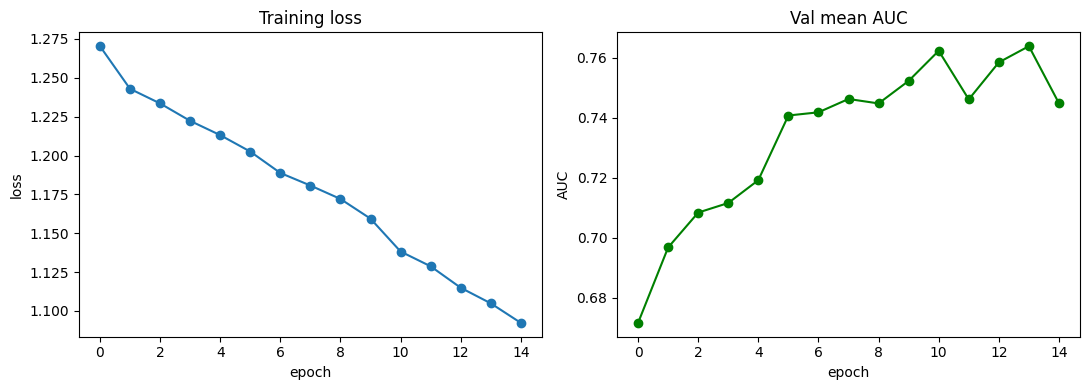

[eval] tuned thresholds: [0.5  0.5  0.55 0.65 0.55 0.55 0.65 0.5 ]

[eval] mean AUC        = 0.7639
[eval] macro-F1        = 0.4883
[eval] micro-F1        = 0.5015
[eval] per-label acc   = 0.7699   (Hamming)
[eval] exact-match acc = 0.0821   (strict, expect low)

              precision    recall  f1-score   support

      Normal       0.40      0.83      0.54       392
    Diabetes       0.42      0.92      0.58       446
    Glaucoma       0.36      0.32      0.34        84
    Cataract       0.66      0.70      0.67        82
         AMD       0.37      0.37      0.37        59
Hypertension       0.16      0.53      0.24        45
      Myopia       0.71      0.81      0.76        67
       Other       0.27      0.80      0.40       327

   micro avg       0.37      0.79      0.50      1502
   macro avg       0.42      0.66      0.49      1502
weighted avg       0.40      0.79      0.51      1502
 samples avg       0.39      0.81      0.49      1502



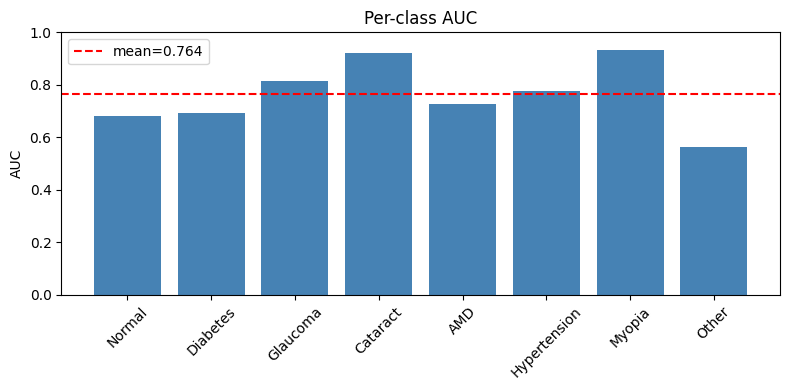

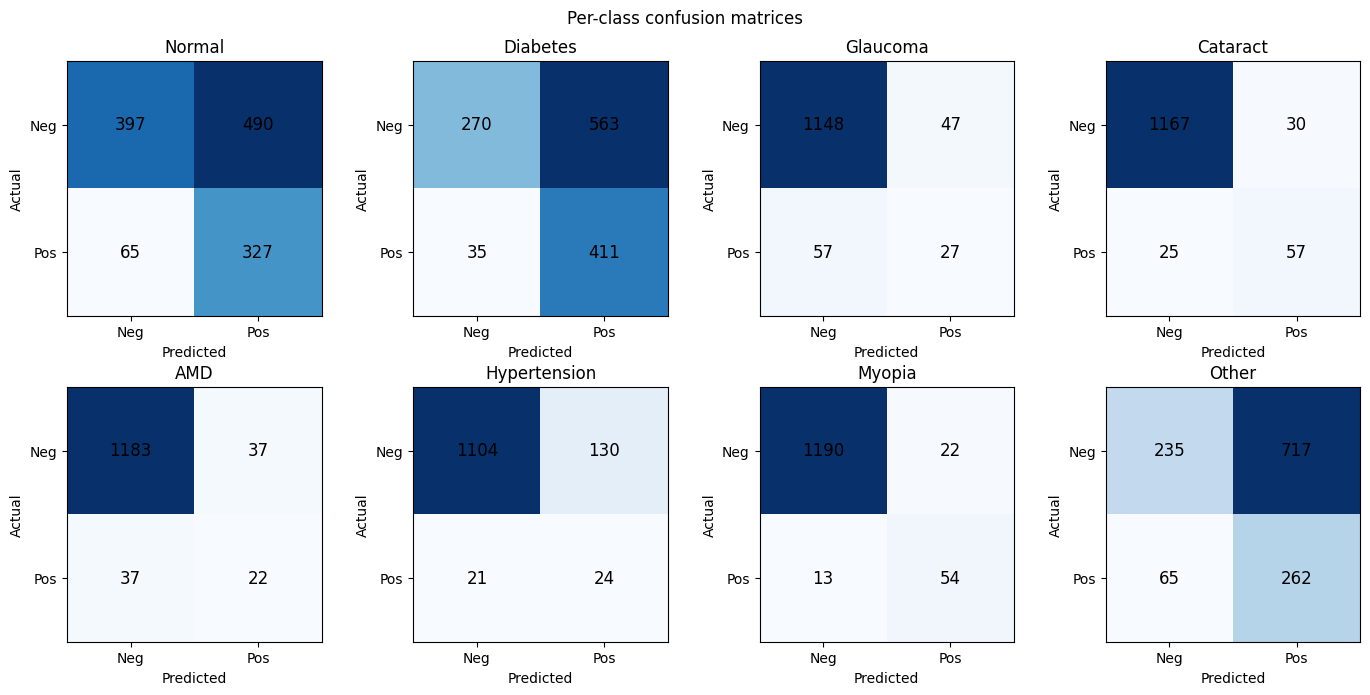


=== 3-OUTPUT DEMO ===
image: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images/3969_right.jpg
1) CLASSIFICATION: Diabetes, Other
3) REPORT:
Findings:
  - Diabetes (conf 0.51): activation in the upper-left region.
  - Other (conf 0.51): activation in the central-left region.

Impression: consistent with Diabetes, Other. Correlate clinically.


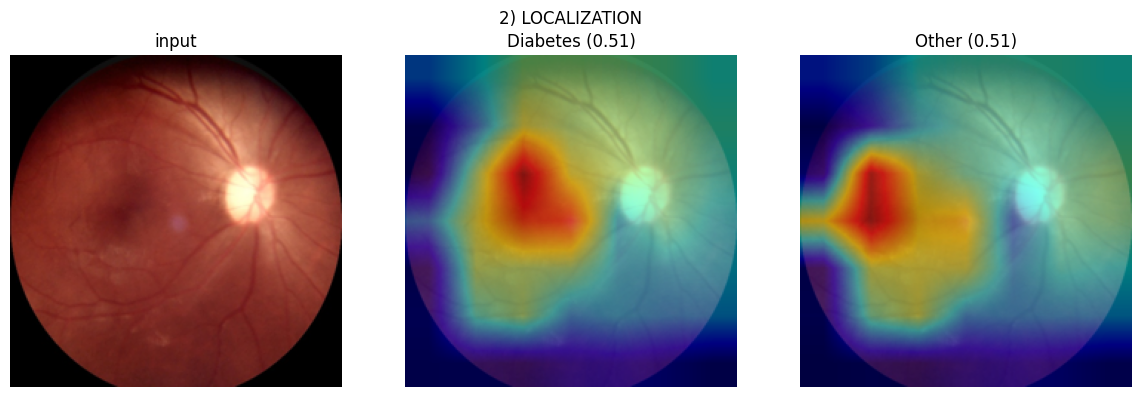


[done] plots saved in /kaggle/working: curves.png auc_bar.png confusion.png demo.png


In [3]:
"""
cipl_odir_full.py  —  ONE runnable pipeline for the sir's brief
================================================================
Does all THREE things, plus training + evaluation + plots + matrices:

    TASK 1  classification  -> multi-label (8 ODIR classes)
    TASK 2  localization    -> colored heatmap mask from prototype similarity maps
    TASK 3  text report     -> short template summary  (NOT in the paper; added here)

    Extras you asked for:
        - correct Kaggle paths, auto-detected + LOUD failure (kills the 0.50 black-image bug)
        - training loop with saved best checkpoint
        - plots: loss curve, mean-AUC curve, per-class AUC bar
        - matrices: 8 per-class confusion matrices + classification report
        - a 3-output demo figure on one validation image

DATASET (default): kaggle andrewmvd/ocular-disease-recognition-odir5k
    /kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/*.jpg
    /kaggle/input/ocular-disease-recognition-odir5k/full_df.csv   (cols N,D,G,C,A,H,M,O + filename)

TWO WAYS TO RUN
    A) TRAIN = True   -> trains a few epochs, then evaluates + plots everything (gives curves)
    B) TRAIN = False  -> loads CKPT (your ~0.79 baseline) and just evaluates + plots

Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
All present on Kaggle.
"""

import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)

try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")


# ======================================================================
# 0. CONFIG  —  edit these
# ======================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR     = "/kaggle/working"
CKPT        = os.path.join(OUT_DIR, "cipl_odir_best.pth")

CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS  = ["N", "D", "G", "C", "A", "H", "M", "O"]   # one-hot cols in full_df.csv
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX  = 0

IMG_SIZE    = 224
BATCH       = 32
EPOCHS      = 15            # a few epochs; raise for better AUC (takes longer)
LR          = 1e-4
THRESHOLD   = 0.5
PROTOS      = 10            # prototypes per class
SEED        = 42

TRAIN       = True         # False -> load CKPT and only evaluate + plot
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")


# ======================================================================
# 1. DATA  —  auto-detect paths/labels, FAIL LOUDLY if wrong
# ======================================================================
def find_image_dir(root):
    for c in ["preprocessed_images",
              "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images",
              "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(
        f"No image folder found under {root}.\n"
        f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")

def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No label CSV found under {root}. Contents: {os.listdir(root)}")

def build_dataframe():
    img_dir = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path}  ({len(df)} rows, cols={list(df.columns)[:6]}...)")

    # -- labels: prefer the 8 one-hot columns; else parse a 'target' list column
    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32)
                           for t in df["target"]])
    else:
        raise KeyError(f"Cannot find labels. Need columns {LABEL_COLS} or 'target'. "
                       f"Got: {list(df.columns)}")

    # -- filename column
    if "filename" in df.columns:
        fnames = df["filename"].astype(str).values
    else:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")

    # -- verify files exist; drop missing LOUDLY (do NOT silently substitute)
    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    n_missing = len(keep) - int(np.sum(keep))
    if n_missing == len(keep):
        raise FileNotFoundError(f"NONE of the {len(keep)} images exist in {img_dir}. "
                                f"Sample expected: {os.path.join(img_dir, fnames[0])}")
    if n_missing:
        print(f"[data] WARNING: {n_missing}/{len(keep)} image files missing -> dropped")
    fnames, labels = fnames[keep], labels[np.array(keep)]
    return img_dir, fnames, labels


class ODIRDataset(Dataset):
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.fnames)

    def __getitem__(self, i):
        # NO bare except here — a bad path must crash, not become a black image
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])


def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds   = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)}  val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True,  num_workers=2),
            DataLoader(val_ds,   BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])


# ======================================================================
# 2. MODEL  —  cosine-prototype net; returns (logits, per-class sim maps)
# ======================================================================
class PrototypeNet(nn.Module):
    """
    features -> [B,2048,h,w] -> 1x1 conv head -> [B,256,h,w]
    prototypes P: [C*M, 256]; cosine sim at each location -> [B, C*M, h, w]
    per-class map = max over that class's M prototypes -> [B, C, h, w]  (localization)
    class logit   = maxpool sim -> [B, C*M] -> Linear -> [B, C]         (classification)
    prototype n belongs to class (n // M)
    """
    def __init__(self, num_classes=NUM_CLASSES, m=PROTOS, feat_dim=256, pretrained=True):
        super().__init__()
        w = "IMAGENET1K_V1" if pretrained else None
        try:
            backbone = torchvision.models.resnet101(weights=w)
        except Exception:                    # no internet on Kaggle -> random init
            backbone = torchvision.models.resnet101(weights=None)
        self.features = nn.Sequential(*list(backbone.children())[:-2])
        self.add_on = nn.Sequential(
            nn.Conv2d(2048, feat_dim, 1), nn.ReLU(),
            nn.Conv2d(feat_dim, feat_dim, 1), nn.Sigmoid())
        self.C, self.M, self.N = num_classes, m, num_classes * m
        self.prototypes = nn.Parameter(torch.rand(self.N, feat_dim))
        self.classifier = nn.Linear(self.N, num_classes)

    def forward(self, x):
        f = self.add_on(self.features(x))                 # [B,D,h,w]
        B, D, h, w = f.shape
        fn = F.normalize(f, dim=1)
        pn = F.normalize(self.prototypes, dim=1)          # [N,D]
        sim = torch.einsum("bdhw,nd->bnhw", fn, pn)       # [B,N,h,w] cosine
        proto_scores = F.adaptive_max_pool2d(sim, 1).flatten(1)     # [B,N]
        logits = self.classifier(proto_scores)                      # [B,C]
        sim_cls = sim.view(B, self.C, self.M, h, w).max(2).values   # [B,C,h,w]
        return logits, sim_cls, proto_scores


# ======================================================================
# 3. LOSS  —  BCE + light clustering/separation (simplified CIPL)
#    (paper also adds cross-attention + 2 alignment losses; omitted for clarity)
# ======================================================================
def compute_pos_weight(train_loader):
    # FIX: rare positives are ~4% of samples -> plain BCE collapses to "all negative".
    # pos_weight = (#neg / #pos) per class upweights positives so they get predicted.
    y = train_loader.dataset.labels                       # [Ntr, C] float
    pos = y.sum(0)
    neg = len(y) - pos
    pw = neg / np.clip(pos, 1, None)
    return torch.tensor(pw, dtype=torch.float32, device=DEVICE)

def cipl_lite_loss(criterion, logits, proto_scores, y, w_clst=0.1, w_sep=0.1):
    B = y.shape[0]
    best = proto_scores.view(B, NUM_CLASSES, PROTOS).max(2).values   # [B,C] best proto sim/class
    pos, neg = y, 1.0 - y
    clst = ((1 - best) * pos).sum() / (pos.sum() + 1e-8)   # positives -> high sim
    sep  = (F.relu(best) * neg).sum() / (neg.sum() + 1e-8) # negatives -> low sim
    return criterion(logits, y) + w_clst * clst + w_sep * sep


# ======================================================================
# 4. TRAIN
# ======================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy())
        Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        if len(np.unique(y_true[:, c])) < 2:
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs

def tune_thresholds(y_true, y_prob):
    # FIX: 0.5 is arbitrary. Pick each class's threshold to maximize its F1.
    # Tuned on TRAIN predictions, then applied to val -> no leakage into reported metrics.
    ths = np.full(NUM_CLASSES, 0.5)
    for c in range(NUM_CLASSES):
        best_f1 = 0.0
        for t in np.linspace(0.05, 0.95, 19):
            f1 = f1_score(y_true[:, c], (y_prob[:, c] > t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, ths[c] = f1, t
    return ths

def train(model, train_loader, val_loader):
    pw = compute_pos_weight(train_loader)                         # FIX: class imbalance
    print("[train] pos_weight:", pw.cpu().numpy().round(1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"loss": [], "auc": []}
    best = -1
    for ep in range(1, EPOCHS + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, ps = model(x)
            loss = cipl_lite_loss(criterion, logits, ps, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        epoch_loss = running / len(train_loader.dataset)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(epoch_loss); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{EPOCHS}  loss={epoch_loss:.4f}  val_mAUC={auc:.4f}")
        if auc > best:
            best = auc; torch.save(model.state_dict(), CKPT)
    print(f"[train] best val mAUC={best:.4f}  saved -> {CKPT}")
    return hist


# ======================================================================
# 5. PLOTS + MATRICES
# ======================================================================
def plot_curves(hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUC")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=120); plt.show()

def plot_auc_bar(aucs):
    plt.figure(figsize=(8, 4))
    vals = [0 if np.isnan(a) else a for a in aucs]
    plt.bar(CLASS_NAMES, vals, color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--",
                label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title("Per-class AUC")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred):
    mcm = multilabel_confusion_matrix(y_true, y_pred)      # [C,2,2]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]
        ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center",
                        color="black", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle("Per-class confusion matrices"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion.png", dpi=120); plt.show()

def evaluate(model, val_loader, thresholds):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > thresholds[None, :]).astype(int)            # FIX: per-class thresholds
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval] mean AUC        = {auc:.4f}")
    print(f"[eval] macro-F1        = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval] micro-F1        = {f1_score(ytrue, ypred, average='micro', zero_division=0):.4f}")
    print(f"[eval] per-label acc   = {(ypred == ytrue).mean():.4f}   (Hamming)")
    print(f"[eval] exact-match acc = {accuracy_score(ytrue, ypred):.4f}   (strict, expect low)\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs)
    plot_confusion(ytrue, ypred)


# ======================================================================
# 6. THREE-OUTPUT DEMO  on one validation image
# ======================================================================
def make_overlay(pil_img, class_map, size=IMG_SIZE):
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)

def peak_region(class_map):
    m = class_map.detach().cpu().numpy()
    y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left"  if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"

def make_report(findings, sim_cls, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f"  - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): "
                     f"activation in the {peak_region(sim_cls[0, c])}.")
    names = ", ".join(CLASS_NAMES[c] for c in findings)
    lines.append(f"\nImpression: consistent with {names}. Correlate clinically.")
    return "\n".join(lines)

_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def demo(model, img_dir, val_fnames, val_labels, thresholds):
    # FIX: pick a val image that actually HAS a disease, so localization shows something
    disease = np.where(val_labels[:, 1:].sum(1) > 0)[0]
    idx = int(disease[0]) if len(disease) else 0
    path = os.path.join(img_dir, val_fnames[idx])
    pil = Image.open(path).convert("RGB")
    x = _demo_tf(pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, sim_cls, _ = model(x)
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES)
                if probs[c] > thresholds[c] and c != NORMAL_IDX]    # FIX: per-class thr

    print("\n=== 3-OUTPUT DEMO ===")
    print("image:", path)
    print("1) CLASSIFICATION:",
          ", ".join(CLASS_NAMES[c] for c in findings) if findings else "Normal")
    print("3) REPORT:\n" + make_report(findings, sim_cls, probs))

    n = 1 + len(findings)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1: axes = [axes]
    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("input")
    axes[0].axis("off")
    for k, c in enumerate(findings, 1):
        axes[k].imshow(make_overlay(pil, sim_cls[0, c]))
        axes[k].set_title(f"{CLASS_NAMES[c]} ({probs[c]:.2f})"); axes[k].axis("off")
    plt.suptitle("2) LOCALIZATION"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo.png", dpi=120); plt.show()


# ======================================================================
# 7. RUN
# ======================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, val_labels = make_loaders()
    model = PrototypeNet().to(DEVICE)

    if TRAIN:
        hist = train(model, train_loader, val_loader)
        plot_curves(hist)
        model.load_state_dict(torch.load(CKPT, map_location=DEVICE))   # reload best
    elif os.path.isfile(CKPT):
        state = torch.load(CKPT, map_location=DEVICE)
        model.load_state_dict(state.get("state_dict", state), strict=False)
        print(f"[model] loaded {CKPT}")
    else:
        print("[model] WARNING: TRAIN=False and no checkpoint -> results meaningless.")

    # FIX: tune per-class thresholds on TRAIN predictions, then use them everywhere
    tr_prob, tr_true = collect(model, train_loader)
    thresholds = tune_thresholds(tr_true, tr_prob)
    print("[eval] tuned thresholds:", thresholds.round(2))

    evaluate(model, val_loader, thresholds)
    demo(model, img_dir, val_fnames, val_labels, thresholds)
    print(f"\n[done] plots saved in {OUT_DIR}: curves.png auc_bar.png confusion.png demo.png")


if __name__ == "__main__":
    main()

[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv  (6392 rows, cols=['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords']...)
[data] train=5113  val=1279
[train] pos_weight: [ 2.   2.  15.3 15.  18.7 31.4 20.4  3.1]
epoch 01/30  loss=1.3012  val_mAUC=0.5758
epoch 02/30  loss=1.2725  val_mAUC=0.5888
epoch 03/30  loss=1.2660  val_mAUC=0.6017
epoch 04/30  loss=1.2628  val_mAUC=0.5786
epoch 05/30  loss=1.2596  val_mAUC=0.6104
epoch 06/30  loss=1.2559  val_mAUC=0.6127
epoch 07/30  loss=1.2534  val_mAUC=0.6231
epoch 08/30  loss=1.2519  val_mAUC=0.6076
epoch 09/30  loss=1.2495  val_mAUC=0.6277
epoch 10/30  loss=1.2452  val_mAUC=0.6301
epoch 11/30  loss=1.2420  val_mAUC=0.6376
epoch 12/30  loss=1.2384  val_mAUC=0.6286
epoch 13/30  loss=1.2349  val_mAUC=0.6376
epoch 14/30  loss=1.2311  val

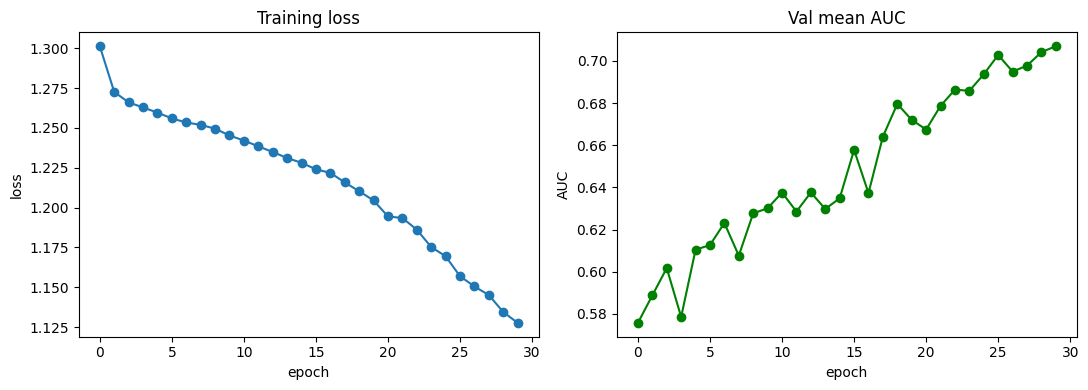

[eval] tuned thresholds: [0.05 0.5  0.55 0.7  0.5  0.55 0.7  0.5 ]

[eval] mean AUC        = 0.7069
[eval] macro-F1        = 0.3703
[eval] micro-F1        = 0.4060
[eval] per-label acc   = 0.6648   (Hamming)
[eval] exact-match acc = 0.0133   (strict, expect low)

              precision    recall  f1-score   support

      Normal       0.31      1.00      0.47       392
    Diabetes       0.43      0.82      0.57       446
    Glaucoma       0.14      0.44      0.21        84
    Cataract       0.36      0.50      0.42        82
         AMD       0.10      0.53      0.16        59
Hypertension       0.06      0.67      0.10        45
      Myopia       0.60      0.67      0.63        67
       Other       0.27      0.70      0.39       327

   micro avg       0.27      0.78      0.41      1502
   macro avg       0.28      0.67      0.37      1502
weighted avg       0.33      0.78      0.45      1502
 samples avg       0.28      0.80      0.40      1502



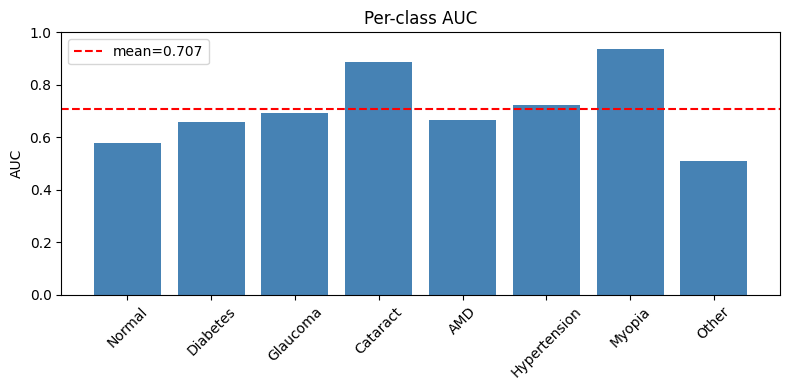

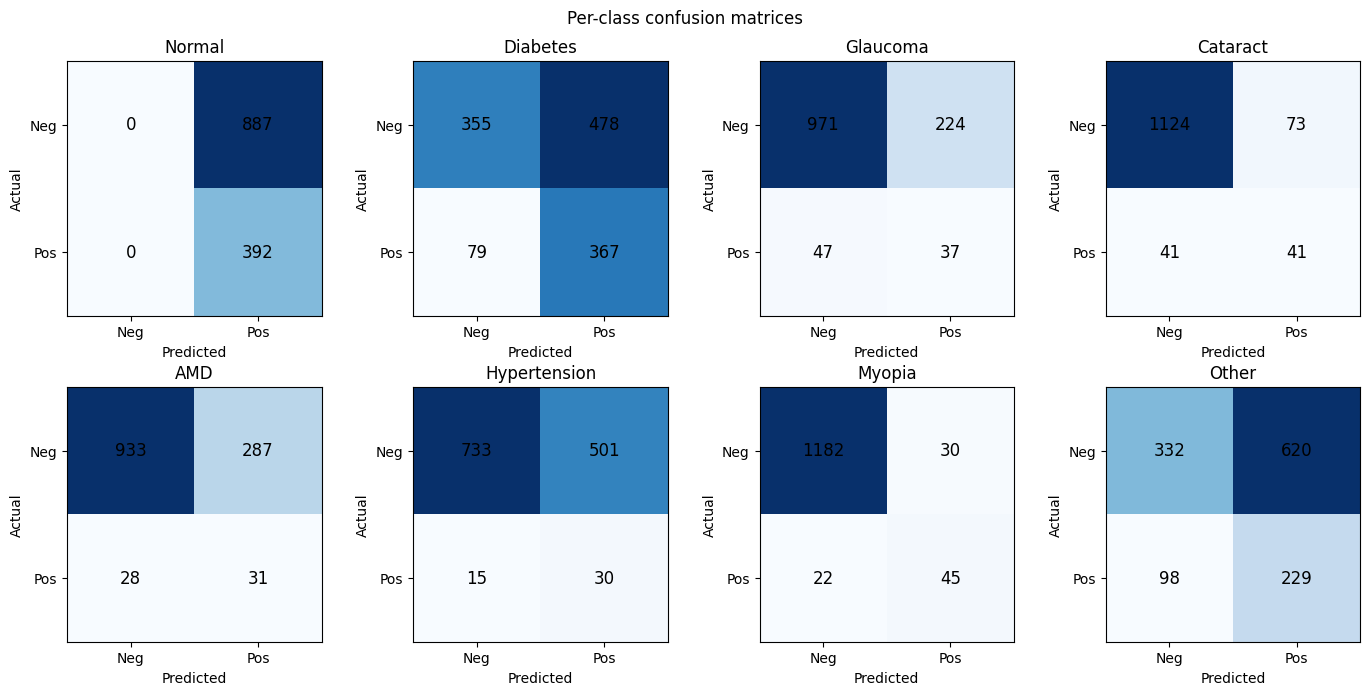


=== 3-OUTPUT DEMO ===
image: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images/3969_right.jpg
1) CLASSIFICATION: Glaucoma
3) REPORT:
Findings:
  - Glaucoma (conf 0.63): activation in the central-left region.

Impression: consistent with Glaucoma. Correlate clinically.


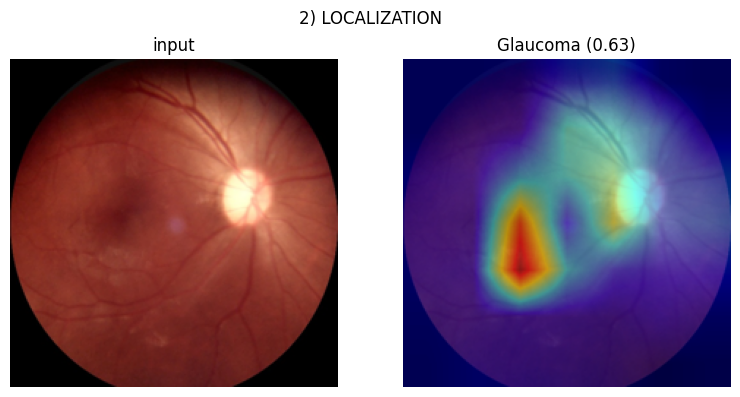


[done] plots saved in /kaggle/working: curves.png auc_bar.png confusion.png demo.png


In [1]:
"""
cipl_odir_full.py  —  ONE runnable pipeline for the sir's brief
================================================================
Does all THREE things, plus training + evaluation + plots + matrices:

    TASK 1  classification  -> multi-label (8 ODIR classes)
    TASK 2  localization    -> colored heatmap mask from prototype similarity maps
    TASK 3  text report     -> short template summary  (NOT in the paper; added here)

    Extras you asked for:
        - correct Kaggle paths, auto-detected + LOUD failure (kills the 0.50 black-image bug)
        - training loop with saved best checkpoint
        - plots: loss curve, mean-AUC curve, per-class AUC bar
        - matrices: 8 per-class confusion matrices + classification report
        - a 3-output demo figure on one validation image

DATASET (default): kaggle andrewmvd/ocular-disease-recognition-odir5k
    /kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/*.jpg
    /kaggle/input/ocular-disease-recognition-odir5k/full_df.csv   (cols N,D,G,C,A,H,M,O + filename)

TWO WAYS TO RUN
    A) TRAIN = True   -> trains a few epochs, then evaluates + plots everything (gives curves)
    B) TRAIN = False  -> loads CKPT (your ~0.79 baseline) and just evaluates + plots

Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
All present on Kaggle.
"""

import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)

try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")


# ======================================================================
# 0. CONFIG  —  edit these
# ======================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR     = "/kaggle/working"
CKPT        = os.path.join(OUT_DIR, "cipl_odir_best.pth")

CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS  = ["N", "D", "G", "C", "A", "H", "M", "O"]   # one-hot cols in full_df.csv
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX  = 0

IMG_SIZE    = 224
BATCH       = 32
EPOCHS      = 30           # from-scratch backbone needs more epochs than pretrained; raise if AUC still climbing
LR          = 1e-4
THRESHOLD   = 0.5
PROTOS      = 10            # prototypes per class
SEED        = 42

TRAIN       = True         # False -> load CKPT and only evaluate + plot
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")


# ======================================================================
# 1. DATA  —  auto-detect paths/labels, FAIL LOUDLY if wrong
# ======================================================================
def find_image_dir(root):
    for c in ["preprocessed_images",
              "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images",
              "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(
        f"No image folder found under {root}.\n"
        f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")

def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No label CSV found under {root}. Contents: {os.listdir(root)}")

def build_dataframe():
    img_dir = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path}  ({len(df)} rows, cols={list(df.columns)[:6]}...)")

    # -- labels: prefer the 8 one-hot columns; else parse a 'target' list column
    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32)
                           for t in df["target"]])
    else:
        raise KeyError(f"Cannot find labels. Need columns {LABEL_COLS} or 'target'. "
                       f"Got: {list(df.columns)}")

    # -- filename column
    if "filename" in df.columns:
        fnames = df["filename"].astype(str).values
    else:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")

    # -- verify files exist; drop missing LOUDLY (do NOT silently substitute)
    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    n_missing = len(keep) - int(np.sum(keep))
    if n_missing == len(keep):
        raise FileNotFoundError(f"NONE of the {len(keep)} images exist in {img_dir}. "
                                f"Sample expected: {os.path.join(img_dir, fnames[0])}")
    if n_missing:
        print(f"[data] WARNING: {n_missing}/{len(keep)} image files missing -> dropped")
    fnames, labels = fnames[keep], labels[np.array(keep)]
    return img_dir, fnames, labels


class ODIRDataset(Dataset):
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.fnames)

    def __getitem__(self, i):
        # NO bare except here — a bad path must crash, not become a black image
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])


def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds   = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)}  val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True,  num_workers=2),
            DataLoader(val_ds,   BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])


# ======================================================================
# 2. MODEL  —  cosine-prototype net; returns (logits, per-class sim maps)
# ======================================================================
class CustomCNN(nn.Module):
    """OUR OWN backbone — built from scratch. NO pretrained weights, NO ResNet/DenseNet.
    5 conv blocks; each block = (Conv 3x3 -> BatchNorm -> ReLU) x2, then MaxPool (halves size).
    224 -> 112 -> 56 -> 28 -> 14 -> 7.   Output feature map: [B, 512, 7, 7]."""
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2))
        self.net = nn.Sequential(
            block(3,   64),     # 224 -> 112
            block(64,  128),    # 112 -> 56
            block(128, 256),    # 56  -> 28
            block(256, 512),    # 28  -> 14
            block(512, 512))    # 14  -> 7
    def forward(self, x):
        return self.net(x)                                # [B, 512, 7, 7]


class PrototypeNet(nn.Module):
    """
    OUR CNN -> [B,512,7,7] -> 1x1 conv head -> [B,256,7,7]
    prototypes P: [C*M, 256]; cosine sim at each location -> [B, C*M, 7, 7]
    per-class map = max over that class's M prototypes -> [B, C, 7, 7]  (segmentation/localization)
    class logit   = maxpool sim -> [B, C*M] -> Linear -> [B, C]         (classification)
    prototype n belongs to class (n // M)
    """
    def __init__(self, num_classes=NUM_CLASSES, m=PROTOS, feat_dim=256):
        super().__init__()
        self.features = CustomCNN()                       # OUR backbone, trained from scratch
        self.add_on = nn.Sequential(
            nn.Conv2d(512, feat_dim, 1), nn.ReLU(),
            nn.Conv2d(feat_dim, feat_dim, 1), nn.Sigmoid())
        self.C, self.M, self.N = num_classes, m, num_classes * m
        self.prototypes = nn.Parameter(torch.rand(self.N, feat_dim))
        self.classifier = nn.Linear(self.N, num_classes)

    def forward(self, x):
        f = self.add_on(self.features(x))                 # [B,256,7,7]
        B, D, h, w = f.shape
        fn = F.normalize(f, dim=1)
        pn = F.normalize(self.prototypes, dim=1)          # [N,D]
        sim = torch.einsum("bdhw,nd->bnhw", fn, pn)       # [B,N,7,7] cosine
        proto_scores = F.adaptive_max_pool2d(sim, 1).flatten(1)     # [B,N]
        logits = self.classifier(proto_scores)                      # [B,C]
        sim_cls = sim.view(B, self.C, self.M, h, w).max(2).values   # [B,C,7,7]
        return logits, sim_cls, proto_scores


# ======================================================================
# 3. LOSS  —  BCE + light clustering/separation (simplified CIPL)
#    (paper also adds cross-attention + 2 alignment losses; omitted for clarity)
# ======================================================================
def compute_pos_weight(train_loader):
    # FIX: rare positives are ~4% of samples -> plain BCE collapses to "all negative".
    # pos_weight = (#neg / #pos) per class upweights positives so they get predicted.
    y = train_loader.dataset.labels                       # [Ntr, C] float
    pos = y.sum(0)
    neg = len(y) - pos
    pw = neg / np.clip(pos, 1, None)
    return torch.tensor(pw, dtype=torch.float32, device=DEVICE)

def cipl_lite_loss(criterion, logits, proto_scores, y, w_clst=0.1, w_sep=0.1):
    B = y.shape[0]
    best = proto_scores.view(B, NUM_CLASSES, PROTOS).max(2).values   # [B,C] best proto sim/class
    pos, neg = y, 1.0 - y
    clst = ((1 - best) * pos).sum() / (pos.sum() + 1e-8)   # positives -> high sim
    sep  = (F.relu(best) * neg).sum() / (neg.sum() + 1e-8) # negatives -> low sim
    return criterion(logits, y) + w_clst * clst + w_sep * sep


# ======================================================================
# 4. TRAIN
# ======================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy())
        Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        if len(np.unique(y_true[:, c])) < 2:
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs

def tune_thresholds(y_true, y_prob):
    # FIX: 0.5 is arbitrary. Pick each class's threshold to maximize its F1.
    # Tuned on TRAIN predictions, then applied to val -> no leakage into reported metrics.
    ths = np.full(NUM_CLASSES, 0.5)
    for c in range(NUM_CLASSES):
        best_f1 = 0.0
        for t in np.linspace(0.05, 0.95, 19):
            f1 = f1_score(y_true[:, c], (y_prob[:, c] > t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, ths[c] = f1, t
    return ths

def train(model, train_loader, val_loader):
    pw = compute_pos_weight(train_loader)                         # FIX: class imbalance
    print("[train] pos_weight:", pw.cpu().numpy().round(1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"loss": [], "auc": []}
    best = -1
    for ep in range(1, EPOCHS + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, ps = model(x)
            loss = cipl_lite_loss(criterion, logits, ps, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        epoch_loss = running / len(train_loader.dataset)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(epoch_loss); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{EPOCHS}  loss={epoch_loss:.4f}  val_mAUC={auc:.4f}")
        if auc > best:
            best = auc; torch.save(model.state_dict(), CKPT)
    print(f"[train] best val mAUC={best:.4f}  saved -> {CKPT}")
    return hist


# ======================================================================
# 5. PLOTS + MATRICES
# ======================================================================
def plot_curves(hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUC")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=120); plt.show()

def plot_auc_bar(aucs):
    plt.figure(figsize=(8, 4))
    vals = [0 if np.isnan(a) else a for a in aucs]
    plt.bar(CLASS_NAMES, vals, color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--",
                label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title("Per-class AUC")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred):
    mcm = multilabel_confusion_matrix(y_true, y_pred)      # [C,2,2]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]
        ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center",
                        color="black", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle("Per-class confusion matrices"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion.png", dpi=120); plt.show()

def evaluate(model, val_loader, thresholds):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > thresholds[None, :]).astype(int)            # FIX: per-class thresholds
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval] mean AUC        = {auc:.4f}")
    print(f"[eval] macro-F1        = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval] micro-F1        = {f1_score(ytrue, ypred, average='micro', zero_division=0):.4f}")
    print(f"[eval] per-label acc   = {(ypred == ytrue).mean():.4f}   (Hamming)")
    print(f"[eval] exact-match acc = {accuracy_score(ytrue, ypred):.4f}   (strict, expect low)\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs)
    plot_confusion(ytrue, ypred)


# ======================================================================
# 6. THREE-OUTPUT DEMO  on one validation image
# ======================================================================
def make_overlay(pil_img, class_map, size=IMG_SIZE):
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)

def peak_region(class_map):
    m = class_map.detach().cpu().numpy()
    y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left"  if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"

def make_report(findings, sim_cls, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f"  - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): "
                     f"activation in the {peak_region(sim_cls[0, c])}.")
    names = ", ".join(CLASS_NAMES[c] for c in findings)
    lines.append(f"\nImpression: consistent with {names}. Correlate clinically.")
    return "\n".join(lines)

_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def demo(model, img_dir, val_fnames, val_labels, thresholds):
    # FIX: pick a val image that actually HAS a disease, so localization shows something
    disease = np.where(val_labels[:, 1:].sum(1) > 0)[0]
    idx = int(disease[0]) if len(disease) else 0
    path = os.path.join(img_dir, val_fnames[idx])
    pil = Image.open(path).convert("RGB")
    x = _demo_tf(pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, sim_cls, _ = model(x)
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES)
                if probs[c] > thresholds[c] and c != NORMAL_IDX]    # FIX: per-class thr

    print("\n=== 3-OUTPUT DEMO ===")
    print("image:", path)
    print("1) CLASSIFICATION:",
          ", ".join(CLASS_NAMES[c] for c in findings) if findings else "Normal")
    print("3) REPORT:\n" + make_report(findings, sim_cls, probs))

    n = 1 + len(findings)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1: axes = [axes]
    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("input")
    axes[0].axis("off")
    for k, c in enumerate(findings, 1):
        axes[k].imshow(make_overlay(pil, sim_cls[0, c]))
        axes[k].set_title(f"{CLASS_NAMES[c]} ({probs[c]:.2f})"); axes[k].axis("off")
    plt.suptitle("2) LOCALIZATION"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo.png", dpi=120); plt.show()


# ======================================================================
# 7. RUN
# ======================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, val_labels = make_loaders()
    model = PrototypeNet().to(DEVICE)

    if TRAIN:
        hist = train(model, train_loader, val_loader)
        plot_curves(hist)
        model.load_state_dict(torch.load(CKPT, map_location=DEVICE))   # reload best
    elif os.path.isfile(CKPT):
        state = torch.load(CKPT, map_location=DEVICE)
        model.load_state_dict(state.get("state_dict", state), strict=False)
        print(f"[model] loaded {CKPT}")
    else:
        print("[model] WARNING: TRAIN=False and no checkpoint -> results meaningless.")

    # FIX: tune per-class thresholds on TRAIN predictions, then use them everywhere
    tr_prob, tr_true = collect(model, train_loader)
    thresholds = tune_thresholds(tr_true, tr_prob)
    print("[eval] tuned thresholds:", thresholds.round(2))

    evaluate(model, val_loader, thresholds)
    demo(model, img_dir, val_fnames, val_labels, thresholds)
    print(f"\n[done] plots saved in {OUT_DIR}: curves.png auc_bar.png confusion.png demo.png")


if __name__ == "__main__":
    main()

[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv (6392 rows, cols=['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords']...)
[data] train=5113 val=1279
[train] pos_weight: [ 2.   2.  15.3 15.  18.7 31.4 20.4  3.1]
epoch 01/5 loss=1.3012 val_mAUC=0.5584
epoch 02/5 loss=1.2729 val_mAUC=0.5989
epoch 03/5 loss=1.2661 val_mAUC=0.5963
epoch 04/5 loss=1.2628 val_mAUC=0.5882
epoch 05/5 loss=1.2603 val_mAUC=0.6022
[train] best val mAUC=0.6022 saved -> /kaggle/working/cipl_odir_best.pth


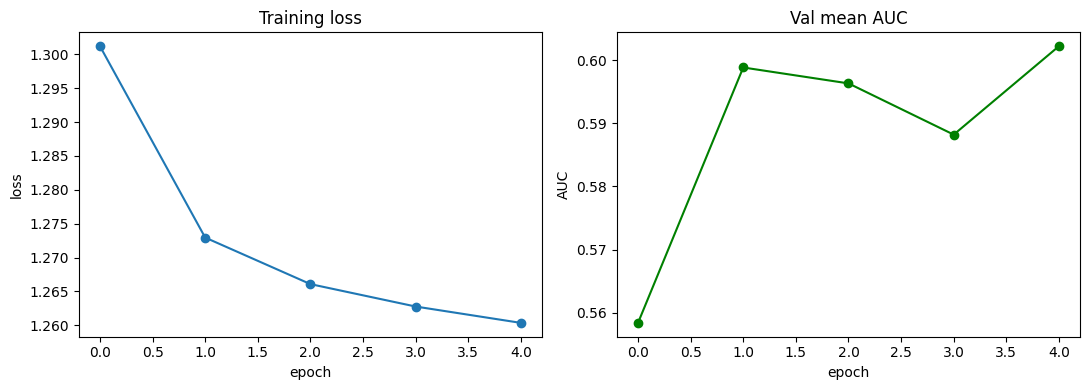

[eval] tuned thresholds: [0.05 0.05 0.5  0.5  0.5  0.5  0.5  0.05]

[eval] mean AUC = 0.6022
[eval] macro-F1 = 0.2690
[eval] micro-F1 = 0.3470
[eval] per-label acc = 0.5031 (Hamming)
[eval] exact-match acc = 0.0000 (strict, expect low)

              precision    recall  f1-score   support

      Normal       0.31      1.00      0.47       392
    Diabetes       0.35      1.00      0.52       446
    Glaucoma       0.09      0.54      0.15        84
    Cataract       0.08      0.63      0.14        82
         AMD       0.06      0.24      0.10        59
Hypertension       0.05      0.84      0.09        45
      Myopia       0.19      0.55      0.29        67
       Other       0.26      1.00      0.41       327

   micro avg       0.21      0.90      0.35      1502
   macro avg       0.17      0.73      0.27      1502
weighted avg       0.26      0.90      0.40      1502
 samples avg       0.22      0.91      0.35      1502



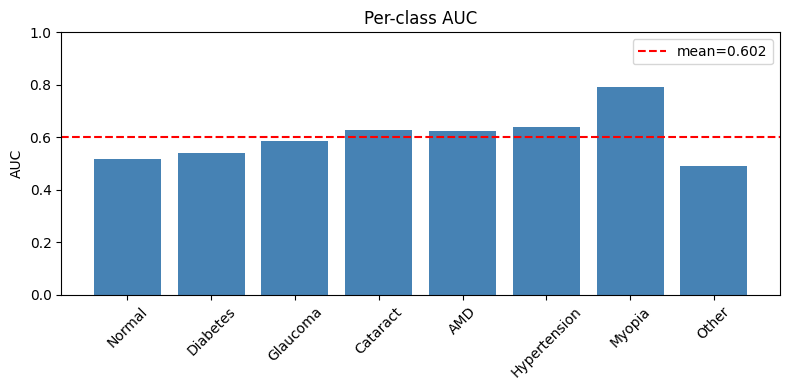

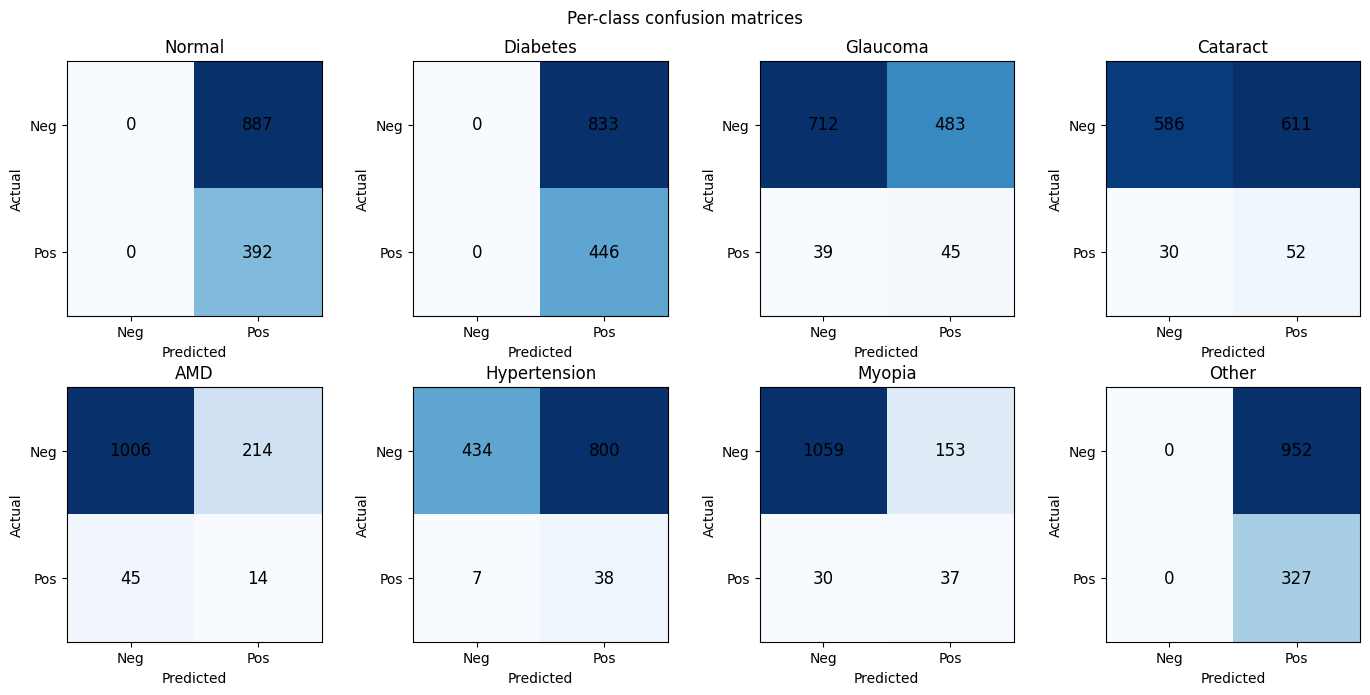


=== 3-OUTPUT + SEGMENTATION DEMO ===
image: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images/3969_right.jpg
1) CLASSIFICATION: Diabetes, Cataract, AMD, Myopia, Other
3) REPORT:
Findings:
 - Diabetes (conf 0.51): activation in the lower-left region.
 - Cataract (conf 0.51): activation in the central (macular) region.
 - AMD (conf 0.51): activation in the central (macular) region.
 - Myopia (conf 0.53): activation in the central-left region.
 - Other (conf 0.51): activation in the upper-left region.

Impression: consistent with Diabetes, Cataract, AMD, Myopia, Other. Correlate clinically.
[seg] saved hard mask -> /kaggle/working/seg_mask_Diabetes.png
[seg] saved hard mask -> /kaggle/working/seg_mask_Cataract.png
[seg] saved hard mask -> /kaggle/working/seg_mask_AMD.png
[seg] saved hard mask -> /kaggle/working/seg_mask_Myopia.png
[seg] saved hard mask -> /kaggle/working/seg_mask_Other.png


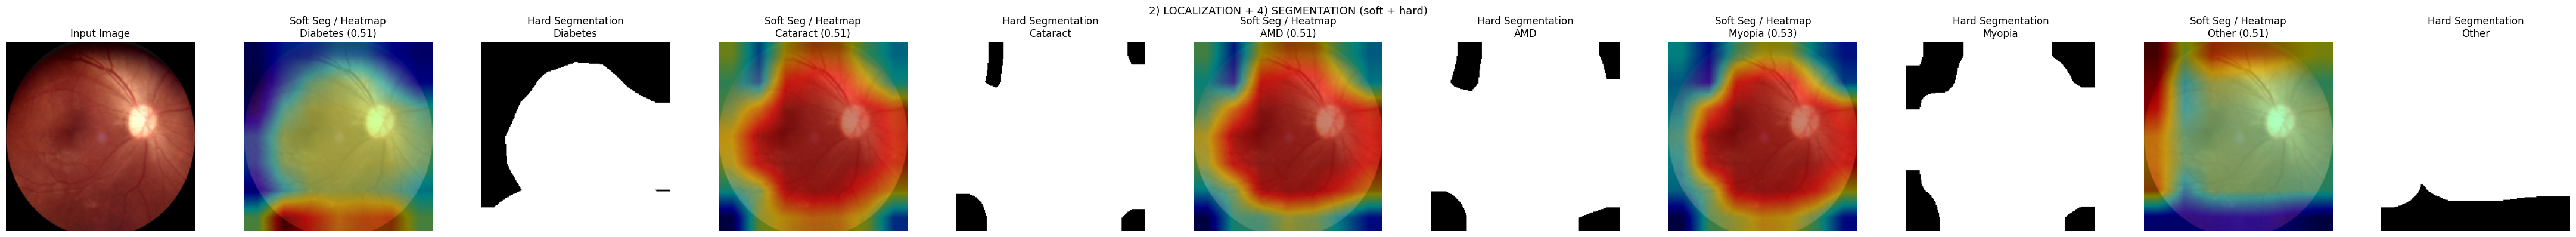


[done] plots saved in /kaggle/working:
  - curves.png
  - auc_bar.png
  - confusion.png
  - demo.png  (classification + soft heatmap + hard segmentation)
  - seg_mask_*.png  (individual hard segmentation masks)


In [1]:
"""
cipl_odir_full.py — ONE runnable pipeline for the sir's brief
================================================================
Does all THREE things, plus training + evaluation + plots + matrices:
    TASK 1 classification -> multi-label (8 ODIR classes)
    TASK 2 localization -> colored heatmap mask from prototype similarity maps
    TASK 3 text report -> short template summary (NOT in the paper; added here)
    + NEW: TASK 4 Segmentation (soft + hard multi-label masks from prototype maps)
    Extras you asked for:
        - correct Kaggle paths, auto-detected + LOUD failure (kills the 0.50 black-image bug)
        - training loop with saved best checkpoint
        - plots: loss curve, mean-AUC curve, per-class AUC bar
        - matrices: 8 per-class confusion matrices + classification report
        - a 3-output demo figure on one validation image
        - NEW: segmentation soft maps + hard masks visualization
DATASET (default): kaggle andrewmvd/ocular-disease-recognition-odir5k
    /kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/*.jpg
    /kaggle/input/ocular-disease-recognition-odir5k/full_df.csv (cols N,D,G,C,A,H,M,O + filename)
TWO WAYS TO RUN
    A) TRAIN = True -> trains a few epochs, then evaluates + plots everything (gives curves)
    B) TRAIN = False -> loads CKPT (your ~0.79 baseline) and just evaluates + plots
Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
All present on Kaggle.
"""
import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)
try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")

# ======================================================================
# 0. CONFIG — edit these
# ======================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR = "/kaggle/working"
CKPT = os.path.join(OUT_DIR, "cipl_odir_best.pth")
CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS = ["N", "D", "G", "C", "A", "H", "M", "O"]  # one-hot cols in full_df.csv
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX = 0
IMG_SIZE = 224
BATCH = 32
EPOCHS = 5         # from-scratch backbone needs more epochs than pretrained; raise if AUC still climbing
LR = 1e-4
THRESHOLD = 0.5
PROTOS = 10          # prototypes per class
SEED = 42
TRAIN = True         # False -> load CKPT and only evaluate + plot
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")

# ======================================================================
# 1. DATA — auto-detect paths/labels, FAIL LOUDLY if wrong
# ======================================================================
def find_image_dir(root):
    for c in ["preprocessed_images",
              "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images",
              "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(
        f"No image folder found under {root}.\n"
        f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")

def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No label CSV found under {root}. Contents: {os.listdir(root)}")

def build_dataframe():
    img_dir = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path} ({len(df)} rows, cols={list(df.columns)[:6]}...)")

    # -- labels: prefer the 8 one-hot columns; else parse a 'target' list column
    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32)
                           for t in df["target"]])
    else:
        raise KeyError(f"Cannot find labels. Need columns {LABEL_COLS} or 'target'. "
                       f"Got: {list(df.columns)}")

    # -- filename column
    if "filename" in df.columns:
        fnames = df["filename"].astype(str).values
    else:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")

    # -- verify files exist; drop missing LOUDLY (do NOT silently substitute)
    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    n_missing = len(keep) - int(np.sum(keep))
    if n_missing == len(keep):
        raise FileNotFoundError(f"NONE of the {len(keep)} images exist in {img_dir}. "
                                f"Sample expected: {os.path.join(img_dir, fnames[0])}")
    if n_missing:
        print(f"[data] WARNING: {n_missing}/{len(keep)} image files missing -> dropped")
    fnames, labels = fnames[keep], labels[np.array(keep)]
    return img_dir, fnames, labels

class ODIRDataset(Dataset):
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])
    def __len__(self):
        return len(self.fnames)
    def __getitem__(self, i):
        # NO bare except here — a bad path must crash, not become a black image
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])

def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)} val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True, num_workers=2),
            DataLoader(val_ds, BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])

# ======================================================================
# 2. MODEL — cosine-prototype net; returns (logits, per-class sim maps)
# ======================================================================
class CustomCNN(nn.Module):
    """OUR OWN backbone — built from scratch. NO pretrained weights, NO ResNet/DenseNet.
    5 conv blocks; each block = (Conv 3x3 -> BatchNorm -> ReLU) x2, then MaxPool (halves size).
    224 -> 112 -> 56 -> 28 -> 14 -> 7. Output feature map: [B, 512, 7, 7]."""
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2))
        self.net = nn.Sequential(
            block(3, 64),   # 224 -> 112
            block(64, 128), # 112 -> 56
            block(128, 256),# 56 -> 28
            block(256, 512),# 28 -> 14
            block(512, 512))# 14 -> 7
    def forward(self, x):
        return self.net(x)  # [B, 512, 7, 7]

class PrototypeNet(nn.Module):
    """
    OUR CNN -> [B,512,7,7] -> 1x1 conv head -> [B,256,7,7]
    prototypes P: [C*M, 256]; cosine sim at each location -> [B, C*M, 7, 7]
    per-class map = max over that class's M prototypes -> [B, C, 7, 7] (segmentation/localization)
    class logit = maxpool sim -> [B, C*M] -> Linear -> [B, C] (classification)
    prototype n belongs to class (n // M)
    """
    def __init__(self, num_classes=NUM_CLASSES, m=PROTOS, feat_dim=256):
        super().__init__()
        self.features = CustomCNN()  # OUR backbone, trained from scratch
        self.add_on = nn.Sequential(
            nn.Conv2d(512, feat_dim, 1), nn.ReLU(),
            nn.Conv2d(feat_dim, feat_dim, 1), nn.Sigmoid())
        self.C, self.M, self.N = num_classes, m, num_classes * m
        self.prototypes = nn.Parameter(torch.rand(self.N, feat_dim))
        self.classifier = nn.Linear(self.N, num_classes)

    def forward(self, x):
        f = self.add_on(self.features(x))          # [B,256,7,7]
        B, D, h, w = f.shape
        fn = F.normalize(f, dim=1)
        pn = F.normalize(self.prototypes, dim=1)   # [N,D]
        sim = torch.einsum("bdhw,nd->bnhw", fn, pn) # [B,N,7,7] cosine
        proto_scores = F.adaptive_max_pool2d(sim, 1).flatten(1)  # [B,N]
        logits = self.classifier(proto_scores)     # [B,C]
        sim_cls = sim.view(B, self.C, self.M, h, w).max(2).values  # [B,C,7,7]
        return logits, sim_cls, proto_scores

# ======================================================================
# 3. LOSS — BCE + light clustering/separation (simplified CIPL)
# (paper also adds cross-attention + 2 alignment losses; omitted for clarity)
# ======================================================================
def compute_pos_weight(train_loader):
    # FIX: rare positives are ~4% of samples -> plain BCE collapses to "all negative".
    # pos_weight = (#neg / #pos) per class upweights positives so they get predicted.
    y = train_loader.dataset.labels  # [Ntr, C] float
    pos = y.sum(0)
    neg = len(y) - pos
    pw = neg / np.clip(pos, 1, None)
    return torch.tensor(pw, dtype=torch.float32, device=DEVICE)

def cipl_lite_loss(criterion, logits, proto_scores, y, w_clst=0.1, w_sep=0.1):
    B = y.shape[0]
    best = proto_scores.view(B, NUM_CLASSES, PROTOS).max(2).values  # [B,C] best proto sim/class
    pos, neg = y, 1.0 - y
    clst = ((1 - best) * pos).sum() / (pos.sum() + 1e-8)  # positives -> high sim
    sep = (F.relu(best) * neg).sum() / (neg.sum() + 1e-8)  # negatives -> low sim
    return criterion(logits, y) + w_clst * clst + w_sep * sep

# ======================================================================
# 4. TRAIN
# ======================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy())
        Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        if len(np.unique(y_true[:, c])) < 2:
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs

def tune_thresholds(y_true, y_prob):
    # FIX: 0.5 is arbitrary. Pick each class's threshold to maximize its F1.
    # Tuned on TRAIN predictions, then applied to val -> no leakage into reported metrics.
    ths = np.full(NUM_CLASSES, 0.5)
    for c in range(NUM_CLASSES):
        best_f1 = 0.0
        for t in np.linspace(0.05, 0.95, 19):
            f1 = f1_score(y_true[:, c], (y_prob[:, c] > t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, ths[c] = f1, t
    return ths

def train(model, train_loader, val_loader):
    pw = compute_pos_weight(train_loader)  # FIX: class imbalance
    print("[train] pos_weight:", pw.cpu().numpy().round(1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"loss": [], "auc": []}
    best = -1
    for ep in range(1, EPOCHS + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, ps = model(x)
            loss = cipl_lite_loss(criterion, logits, ps, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        epoch_loss = running / len(train_loader.dataset)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(epoch_loss); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{EPOCHS} loss={epoch_loss:.4f} val_mAUC={auc:.4f}")
        if auc > best:
            best = auc; torch.save(model.state_dict(), CKPT)
    print(f"[train] best val mAUC={best:.4f} saved -> {CKPT}")
    return hist

# ======================================================================
# 5. PLOTS + MATRICES
# ======================================================================
def plot_curves(hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUC")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=120); plt.show()

def plot_auc_bar(aucs):
    plt.figure(figsize=(8, 4))
    vals = [0 if np.isnan(a) else a for a in aucs]
    plt.bar(CLASS_NAMES, vals, color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--",
                label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title("Per-class AUC")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred):
    mcm = multilabel_confusion_matrix(y_true, y_pred)  # [C,2,2]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]
        ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center",
                        color="black", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle("Per-class confusion matrices"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion.png", dpi=120); plt.show()

def evaluate(model, val_loader, thresholds):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > thresholds[None, :]).astype(int)  # FIX: per-class thresholds
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval] mean AUC = {auc:.4f}")
    print(f"[eval] macro-F1 = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval] micro-F1 = {f1_score(ytrue, ypred, average='micro', zero_division=0):.4f}")
    print(f"[eval] per-label acc = {(ypred == ytrue).mean():.4f} (Hamming)")
    print(f"[eval] exact-match acc = {accuracy_score(ytrue, ypred):.4f} (strict, expect low)\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs)
    plot_confusion(ytrue, ypred)

# ======================================================================
# 6. THREE-OUTPUT DEMO + SEGMENTATION on one validation image
# ======================================================================
def make_overlay(pil_img, class_map, size=IMG_SIZE):
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)

def make_hard_mask(class_map, size=IMG_SIZE, thr=0.4):
    """Convert soft similarity map -> binary segmentation mask"""
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    if cv2 is not None:
        m = cv2.resize(m, (size, size))
    else:
        from PIL import Image as PILImage
        m = np.array(PILImage.fromarray((m*255).astype(np.uint8)).resize((size, size))) / 255.0
    hard = (m > thr).astype(np.uint8) * 255
    return hard

def peak_region(class_map):
    m = class_map.detach().cpu().numpy()
    y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left" if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"

def make_report(findings, sim_cls, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f" - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): "
                     f"activation in the {peak_region(sim_cls[0, c])}.")
    names = ", ".join(CLASS_NAMES[c] for c in findings)
    lines.append(f"\nImpression: consistent with {names}. Correlate clinically.")
    return "\n".join(lines)

_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def demo(model, img_dir, val_fnames, val_labels, thresholds):
    # FIX: pick a val image that actually HAS a disease, so localization shows something
    disease = np.where(val_labels[:, 1:].sum(1) > 0)[0]
    idx = int(disease[0]) if len(disease) else 0
    path = os.path.join(img_dir, val_fnames[idx])
    pil = Image.open(path).convert("RGB")
    x = _demo_tf(pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, sim_cls, _ = model(x)
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES)
                if probs[c] > thresholds[c] and c != NORMAL_IDX]  # FIX: per-class thr

    print("\n=== 3-OUTPUT + SEGMENTATION DEMO ===")
    print("image:", path)
    print("1) CLASSIFICATION:",
          ", ".join(CLASS_NAMES[c] for c in findings) if findings else "Normal")
    print("3) REPORT:\n" + make_report(findings, sim_cls, probs))

    # ---------- Visualization: input + soft heatmaps + hard segmentation masks ----------
    n = 1 + len(findings) * 2   # input + (heatmap + hard mask) for each finding
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(5, 5))
        axes = [axes]
    else:
        fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE)))
    axes[0].set_title("Input Image")
    axes[0].axis("off")

    for k, c in enumerate(findings):
        # Soft heatmap (localization)
        axes[1 + 2*k].imshow(make_overlay(pil, sim_cls[0, c]))
        axes[1 + 2*k].set_title(f"Soft Seg / Heatmap\n{CLASS_NAMES[c]} ({probs[c]:.2f})")
        axes[1 + 2*k].axis("off")

        # Hard binary segmentation mask
        hard = make_hard_mask(sim_cls[0, c], thr=0.35)
        axes[2 + 2*k].imshow(hard, cmap="gray")
        axes[2 + 2*k].set_title(f"Hard Segmentation\n{CLASS_NAMES[c]}")
        axes[2 + 2*k].axis("off")

        # Also save the hard mask to disk
        mask_path = os.path.join(OUT_DIR, f"seg_mask_{CLASS_NAMES[c]}.png")
        Image.fromarray(hard).save(mask_path)
        print(f"[seg] saved hard mask -> {mask_path}")

    plt.suptitle("2) LOCALIZATION + 4) SEGMENTATION (soft + hard)", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo.png", dpi=130)
    plt.show()

# ======================================================================
# 7. RUN
# ======================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, val_labels = make_loaders()
    model = PrototypeNet().to(DEVICE)

    if TRAIN:
        hist = train(model, train_loader, val_loader)
        plot_curves(hist)
        model.load_state_dict(torch.load(CKPT, map_location=DEVICE))  # reload best
    elif os.path.isfile(CKPT):
        state = torch.load(CKPT, map_location=DEVICE)
        model.load_state_dict(state.get("state_dict", state), strict=False)
        print(f"[model] loaded {CKPT}")
    else:
        print("[model] WARNING: TRAIN=False and no checkpoint -> results meaningless.")

    # FIX: tune per-class thresholds on TRAIN predictions, then use them everywhere
    tr_prob, tr_true = collect(model, train_loader)
    thresholds = tune_thresholds(tr_true, tr_prob)
    print("[eval] tuned thresholds:", thresholds.round(2))

    evaluate(model, val_loader, thresholds)
    demo(model, img_dir, val_fnames, val_labels, thresholds)

    print(f"\n[done] plots saved in {OUT_DIR}:")
    print("  - curves.png")
    print("  - auc_bar.png")
    print("  - confusion.png")
    print("  - demo.png  (classification + soft heatmap + hard segmentation)")
    print("  - seg_mask_*.png  (individual hard segmentation masks)")

if __name__ == "__main__":
    main()

[info] device = cuda
[data] images: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images
[data] labels: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/full_df.csv (6392 rows, cols=['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords']...)
[data] train=5113 val=1279
[train] pos_weight: [ 2.   2.  15.3 15.  18.7 31.4 20.4  3.1]
epoch 01/30 loss=1.3009 val_mAUC=0.5674
epoch 02/30 loss=1.2729 val_mAUC=0.5701
epoch 03/30 loss=1.2664 val_mAUC=0.5896
epoch 04/30 loss=1.2622 val_mAUC=0.6074
epoch 05/30 loss=1.2608 val_mAUC=0.6204
epoch 06/30 loss=1.2570 val_mAUC=0.6044
epoch 07/30 loss=1.2532 val_mAUC=0.6163
epoch 08/30 loss=1.2514 val_mAUC=0.6106
epoch 09/30 loss=1.2491 val_mAUC=0.6231
epoch 10/30 loss=1.2454 val_mAUC=0.6173
epoch 11/30 loss=1.2425 val_mAUC=0.6103
epoch 12/30 loss=1.2404 val_mAUC=0.6180
epoch 13/30 loss=1.2373 val_mAUC=0.6335
epoch 14/30 loss=1.2351 val_mAUC=0.6061
epoch 15/30 loss=

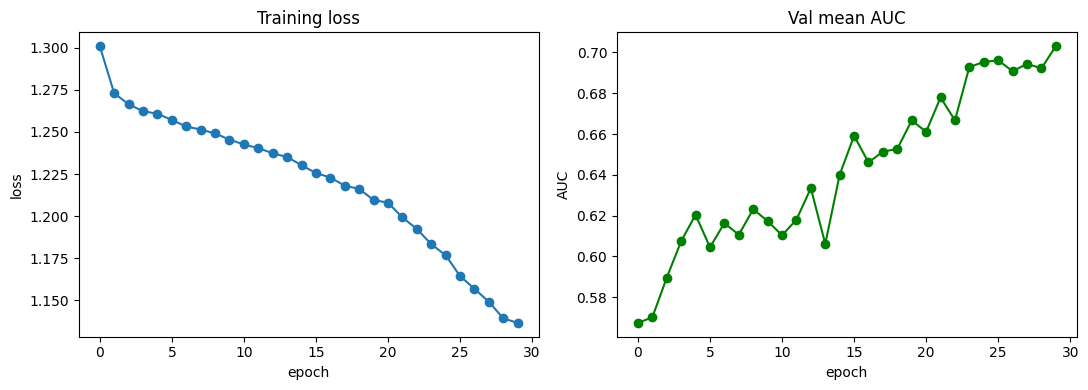

[eval] tuned thresholds: [0.05 0.55 0.45 0.7  0.5  0.55 0.7  0.5 ]

[eval] mean AUC = 0.7031
[eval] macro-F1 = 0.3833
[eval] micro-F1 = 0.3761
[eval] per-label acc = 0.6209 (Hamming)
[eval] exact-match acc = 0.0039 (strict, expect low)

              precision    recall  f1-score   support

      Normal       0.31      1.00      0.47       392
    Diabetes       0.45      0.71      0.55       446
    Glaucoma       0.16      0.54      0.24        84
    Cataract       0.62      0.52      0.57        82
         AMD       0.06      0.81      0.11        59
Hypertension       0.05      0.67      0.09        45
      Myopia       0.60      0.66      0.63        67
       Other       0.27      0.76      0.40       327

   micro avg       0.25      0.78      0.38      1502
   macro avg       0.31      0.71      0.38      1502
weighted avg       0.34      0.78      0.45      1502
 samples avg       0.26      0.80      0.38      1502



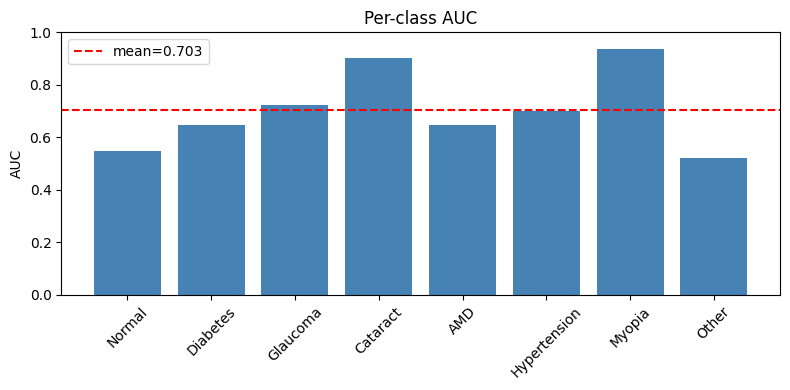

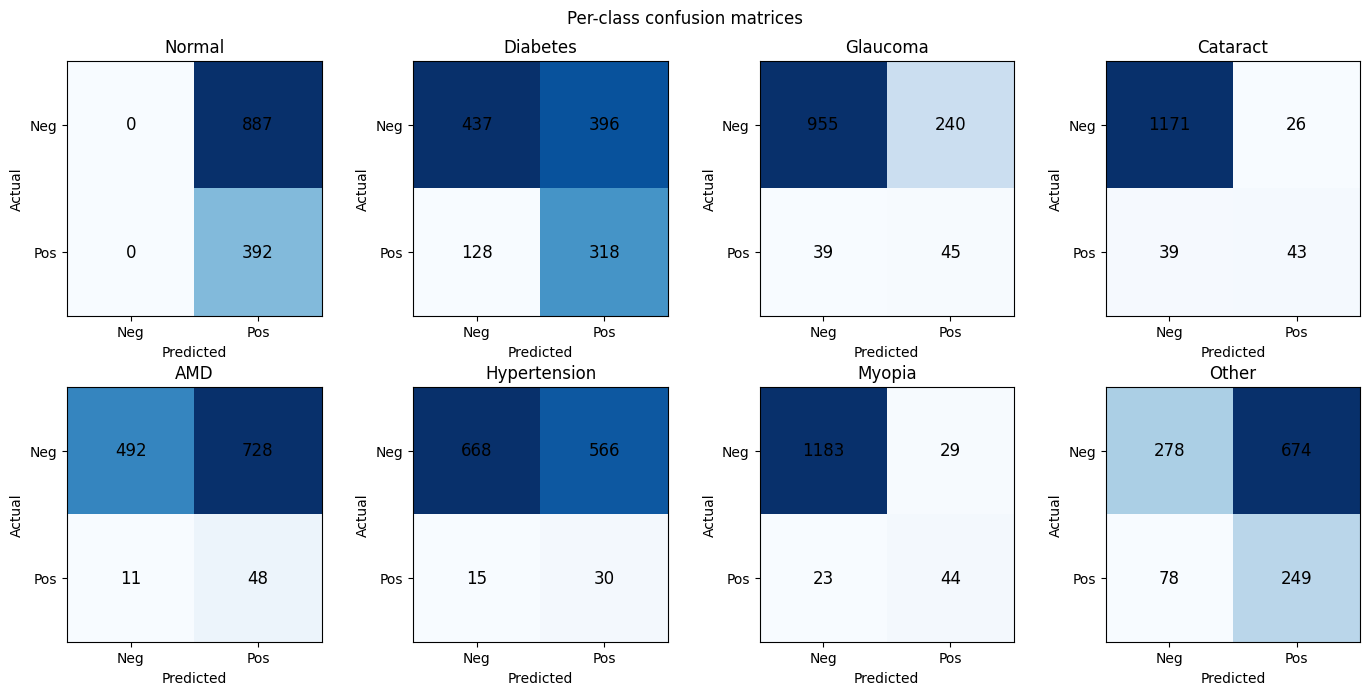


=== 3-OUTPUT + SEGMENTATION DEMO ===
image: /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k/preprocessed_images/3969_right.jpg
1) CLASSIFICATION: Glaucoma, AMD
3) REPORT:
Findings:
 - Glaucoma (conf 0.48): activation in the upper-central region.
 - AMD (conf 0.51): activation in the upper-central region.

Impression: consistent with Glaucoma, AMD. Correlate clinically.
[seg] saved hard mask -> /kaggle/working/seg_mask_Glaucoma.png
[seg] saved hard mask -> /kaggle/working/seg_mask_AMD.png


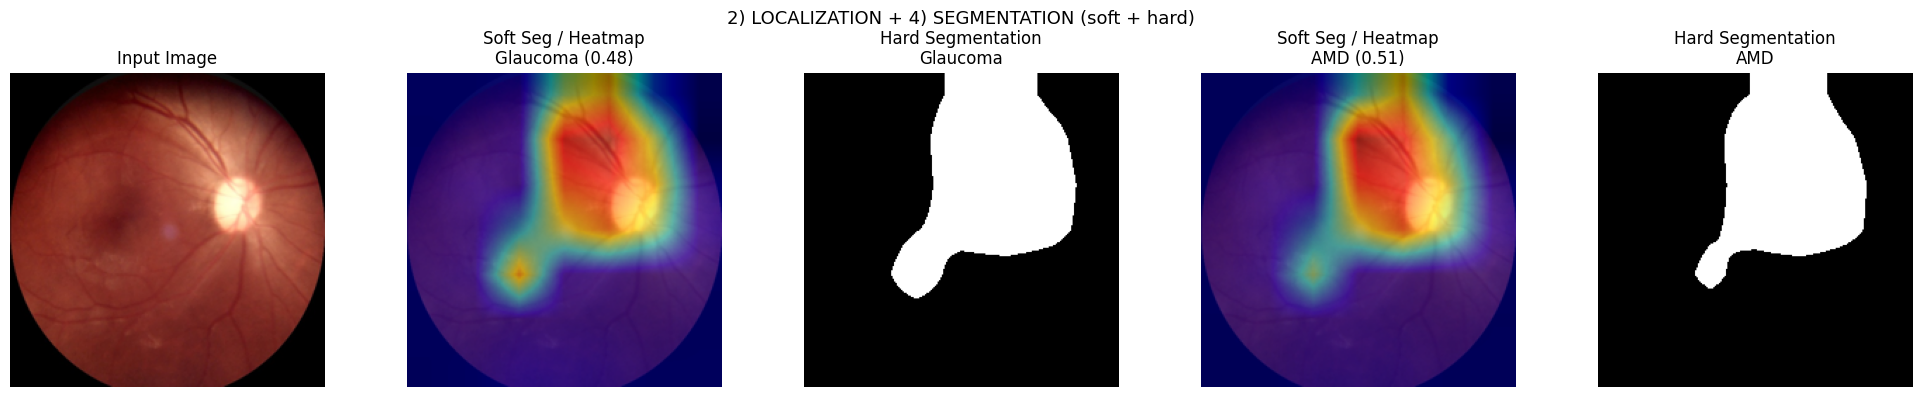


[done] plots saved in /kaggle/working:
  - curves.png
  - auc_bar.png
  - confusion.png
  - demo.png  (classification + soft heatmap + hard segmentation)
  - seg_mask_*.png  (individual hard segmentation masks)


In [1]:
"""
cipl_odir_full.py — ONE runnable pipeline for the sir's brief
================================================================
Does all THREE things, plus training + evaluation + plots + matrices:
    TASK 1 classification -> multi-label (8 ODIR classes)
    TASK 2 localization -> colored heatmap mask from prototype similarity maps
    TASK 3 text report -> short template summary (NOT in the paper; added here)
    + NEW: TASK 4 Segmentation (soft + hard multi-label masks from prototype maps)
    Extras you asked for:
        - correct Kaggle paths, auto-detected + LOUD failure (kills the 0.50 black-image bug)
        - training loop with saved best checkpoint
        - plots: loss curve, mean-AUC curve, per-class AUC bar
        - matrices: 8 per-class confusion matrices + classification report
        - a 3-output demo figure on one validation image
        - NEW: segmentation soft maps + hard masks visualization
DATASET (default): kaggle andrewmvd/ocular-disease-recognition-odir5k
    /kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/*.jpg
    /kaggle/input/ocular-disease-recognition-odir5k/full_df.csv (cols N,D,G,C,A,H,M,O + filename)
TWO WAYS TO RUN
    A) TRAIN = True -> trains a few epochs, then evaluates + plots everything (gives curves)
    B) TRAIN = False -> loads CKPT (your ~0.79 baseline) and just evaluates + plots
Needs: torch, torchvision, numpy, pandas, scikit-learn, matplotlib, pillow, opencv-python
All present on Kaggle.
"""
import os, ast, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, multilabel_confusion_matrix,
                             classification_report, f1_score, accuracy_score)
try:
    import cv2
except ImportError:
    cv2 = None
warnings.filterwarnings("ignore")

# ======================================================================
# 0. CONFIG — edit these
# ======================================================================
DATA_ROOT = "/kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k"
OUT_DIR = "/kaggle/working"
CKPT = os.path.join(OUT_DIR, "cipl_odir_best.pth")
CLASS_NAMES = ["Normal", "Diabetes", "Glaucoma", "Cataract",
               "AMD", "Hypertension", "Myopia", "Other"]
LABEL_COLS = ["N", "D", "G", "C", "A", "H", "M", "O"]  # one-hot cols in full_df.csv
NUM_CLASSES = len(CLASS_NAMES)
NORMAL_IDX = 0
IMG_SIZE = 224
BATCH = 32
EPOCHS = 30       # from-scratch backbone needs more epochs than pretrained; raise if AUC still climbing
LR = 1e-4
THRESHOLD = 0.5
PROTOS = 10          # prototypes per class
SEED = 42
TRAIN = True         # False -> load CKPT and only evaluate + plot
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"[info] device = {DEVICE}")

# ======================================================================
# 1. DATA — auto-detect paths/labels, FAIL LOUDLY if wrong
# ======================================================================
def find_image_dir(root):
    for c in ["preprocessed_images",
              "ODIR-5K/ODIR-5K/Training Images",
              "ODIR-5K/Training Images",
              "Training Images"]:
        p = os.path.join(root, c)
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(
        f"No image folder found under {root}.\n"
        f"Contents: {os.listdir(root) if os.path.isdir(root) else 'ROOT MISSING'}")

def find_csv(root):
    for c in ["full_df.csv", "data.csv", "odir.csv"]:
        p = os.path.join(root, c)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        f"No label CSV found under {root}. Contents: {os.listdir(root)}")

def build_dataframe():
    img_dir = find_image_dir(DATA_ROOT)
    csv_path = find_csv(DATA_ROOT)
    df = pd.read_csv(csv_path)
    print(f"[data] images: {img_dir}")
    print(f"[data] labels: {csv_path} ({len(df)} rows, cols={list(df.columns)[:6]}...)")

    # -- labels: prefer the 8 one-hot columns; else parse a 'target' list column
    if set(LABEL_COLS).issubset(df.columns):
        labels = df[LABEL_COLS].values.astype(np.float32)
    elif "target" in df.columns:
        labels = np.stack([np.array(ast.literal_eval(t), dtype=np.float32)
                           for t in df["target"]])
    else:
        raise KeyError(f"Cannot find labels. Need columns {LABEL_COLS} or 'target'. "
                       f"Got: {list(df.columns)}")

    # -- filename column
    if "filename" in df.columns:
        fnames = df["filename"].astype(str).values
    else:
        raise KeyError(f"Need a 'filename' column. Got: {list(df.columns)}")

    # -- verify files exist; drop missing LOUDLY (do NOT silently substitute)
    keep = [os.path.isfile(os.path.join(img_dir, f)) for f in fnames]
    n_missing = len(keep) - int(np.sum(keep))
    if n_missing == len(keep):
        raise FileNotFoundError(f"NONE of the {len(keep)} images exist in {img_dir}. "
                                f"Sample expected: {os.path.join(img_dir, fnames[0])}")
    if n_missing:
        print(f"[data] WARNING: {n_missing}/{len(keep)} image files missing -> dropped")
    fnames, labels = fnames[keep], labels[np.array(keep)]
    return img_dir, fnames, labels

class ODIRDataset(Dataset):
    def __init__(self, img_dir, fnames, labels, train=False):
        self.img_dir, self.fnames, self.labels = img_dir, fnames, labels
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(10)] if train else []
        self.tf = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])
    def __len__(self):
        return len(self.fnames)
    def __getitem__(self, i):
        # NO bare except here — a bad path must crash, not become a black image
        img = Image.open(os.path.join(self.img_dir, self.fnames[i])).convert("RGB")
        return self.tf(img), torch.tensor(self.labels[i])

def make_loaders():
    img_dir, fnames, labels = build_dataframe()
    idx = np.arange(len(fnames))
    tr, va = train_test_split(idx, test_size=0.2, random_state=SEED)
    train_ds = ODIRDataset(img_dir, fnames[tr], labels[tr], train=True)
    val_ds = ODIRDataset(img_dir, fnames[va], labels[va], train=False)
    print(f"[data] train={len(train_ds)} val={len(val_ds)}")
    return (DataLoader(train_ds, BATCH, shuffle=True, num_workers=2),
            DataLoader(val_ds, BATCH, shuffle=False, num_workers=2),
            img_dir, fnames[va], labels[va])

# ======================================================================
# 2. MODEL — cosine-prototype net; returns (logits, per-class sim maps)
# ======================================================================
class CustomCNN(nn.Module):
    """OUR OWN backbone — built from scratch. NO pretrained weights, NO ResNet/DenseNet.
    5 conv blocks; each block = (Conv 3x3 -> BatchNorm -> ReLU) x2, then MaxPool (halves size).
    224 -> 112 -> 56 -> 28 -> 14 -> 7. Output feature map: [B, 512, 7, 7]."""
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2))
        self.net = nn.Sequential(
            block(3, 64),   # 224 -> 112
            block(64, 128), # 112 -> 56
            block(128, 256),# 56 -> 28
            block(256, 512),# 28 -> 14
            block(512, 512))# 14 -> 7
    def forward(self, x):
        return self.net(x)  # [B, 512, 7, 7]

class PrototypeNet(nn.Module):
    """
    OUR CNN -> [B,512,7,7] -> 1x1 conv head -> [B,256,7,7]
    prototypes P: [C*M, 256]; cosine sim at each location -> [B, C*M, 7, 7]
    per-class map = max over that class's M prototypes -> [B, C, 7, 7] (segmentation/localization)
    class logit = maxpool sim -> [B, C*M] -> Linear -> [B, C] (classification)
    prototype n belongs to class (n // M)
    """
    def __init__(self, num_classes=NUM_CLASSES, m=PROTOS, feat_dim=256):
        super().__init__()
        self.features = CustomCNN()  # OUR backbone, trained from scratch
        self.add_on = nn.Sequential(
            nn.Conv2d(512, feat_dim, 1), nn.ReLU(),
            nn.Conv2d(feat_dim, feat_dim, 1), nn.Sigmoid())
        self.C, self.M, self.N = num_classes, m, num_classes * m
        self.prototypes = nn.Parameter(torch.rand(self.N, feat_dim))
        self.classifier = nn.Linear(self.N, num_classes)

    def forward(self, x):
        f = self.add_on(self.features(x))          # [B,256,7,7]
        B, D, h, w = f.shape
        fn = F.normalize(f, dim=1)
        pn = F.normalize(self.prototypes, dim=1)   # [N,D]
        sim = torch.einsum("bdhw,nd->bnhw", fn, pn) # [B,N,7,7] cosine
        proto_scores = F.adaptive_max_pool2d(sim, 1).flatten(1)  # [B,N]
        logits = self.classifier(proto_scores)     # [B,C]
        sim_cls = sim.view(B, self.C, self.M, h, w).max(2).values  # [B,C,7,7]
        return logits, sim_cls, proto_scores

# ======================================================================
# 3. LOSS — BCE + light clustering/separation (simplified CIPL)
# (paper also adds cross-attention + 2 alignment losses; omitted for clarity)
# ======================================================================
def compute_pos_weight(train_loader):
    # FIX: rare positives are ~4% of samples -> plain BCE collapses to "all negative".
    # pos_weight = (#neg / #pos) per class upweights positives so they get predicted.
    y = train_loader.dataset.labels  # [Ntr, C] float
    pos = y.sum(0)
    neg = len(y) - pos
    pw = neg / np.clip(pos, 1, None)
    return torch.tensor(pw, dtype=torch.float32, device=DEVICE)

def cipl_lite_loss(criterion, logits, proto_scores, y, w_clst=0.1, w_sep=0.1):
    B = y.shape[0]
    best = proto_scores.view(B, NUM_CLASSES, PROTOS).max(2).values  # [B,C] best proto sim/class
    pos, neg = y, 1.0 - y
    clst = ((1 - best) * pos).sum() / (pos.sum() + 1e-8)  # positives -> high sim
    sep = (F.relu(best) * neg).sum() / (neg.sum() + 1e-8)  # negatives -> low sim
    return criterion(logits, y) + w_clst * clst + w_sep * sep

# ======================================================================
# 4. TRAIN
# ======================================================================
@torch.no_grad()
def collect(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        logits, _, _ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logits).cpu().numpy())
        Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def mean_auc(y_true, y_prob):
    aucs = []
    for c in range(NUM_CLASSES):
        if len(np.unique(y_true[:, c])) < 2:
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, c], y_prob[:, c]))
    return float(np.nanmean(aucs)), aucs

def tune_thresholds(y_true, y_prob):
    # FIX: 0.5 is arbitrary. Pick each class's threshold to maximize its F1.
    # Tuned on TRAIN predictions, then applied to val -> no leakage into reported metrics.
    ths = np.full(NUM_CLASSES, 0.5)
    for c in range(NUM_CLASSES):
        best_f1 = 0.0
        for t in np.linspace(0.05, 0.95, 19):
            f1 = f1_score(y_true[:, c], (y_prob[:, c] > t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, ths[c] = f1, t
    return ths

def train(model, train_loader, val_loader):
    pw = compute_pos_weight(train_loader)  # FIX: class imbalance
    print("[train] pos_weight:", pw.cpu().numpy().round(1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"loss": [], "auc": []}
    best = -1
    for ep in range(1, EPOCHS + 1):
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _, ps = model(x)
            loss = cipl_lite_loss(criterion, logits, ps, y)
            loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        epoch_loss = running / len(train_loader.dataset)
        yprob, ytrue = collect(model, val_loader)
        auc, _ = mean_auc(ytrue, yprob)
        hist["loss"].append(epoch_loss); hist["auc"].append(auc)
        print(f"epoch {ep:02d}/{EPOCHS} loss={epoch_loss:.4f} val_mAUC={auc:.4f}")
        if auc > best:
            best = auc; torch.save(model.state_dict(), CKPT)
    print(f"[train] best val mAUC={best:.4f} saved -> {CKPT}")
    return hist

# ======================================================================
# 5. PLOTS + MATRICES
# ======================================================================
def plot_curves(hist):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"], marker="o"); ax[0].set_title("Training loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
    ax[1].plot(hist["auc"], marker="o", color="green"); ax[1].set_title("Val mean AUC")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUC")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=120); plt.show()

def plot_auc_bar(aucs):
    plt.figure(figsize=(8, 4))
    vals = [0 if np.isnan(a) else a for a in aucs]
    plt.bar(CLASS_NAMES, vals, color="steelblue")
    plt.axhline(np.nanmean(aucs), color="red", ls="--",
                label=f"mean={np.nanmean(aucs):.3f}")
    plt.ylim(0, 1); plt.ylabel("AUC"); plt.title("Per-class AUC")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/auc_bar.png", dpi=120); plt.show()

def plot_confusion(y_true, y_pred):
    mcm = multilabel_confusion_matrix(y_true, y_pred)  # [C,2,2]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for c, ax in enumerate(axes.flat):
        m = mcm[c]
        ax.imshow(m, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, m[i, j], ha="center", va="center",
                        color="black", fontsize=12)
        ax.set_title(CLASS_NAMES[c]); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle("Per-class confusion matrices"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/confusion.png", dpi=120); plt.show()

def evaluate(model, val_loader, thresholds):
    yprob, ytrue = collect(model, val_loader)
    ypred = (yprob > thresholds[None, :]).astype(int)  # FIX: per-class thresholds
    auc, aucs = mean_auc(ytrue, yprob)
    print(f"\n[eval] mean AUC = {auc:.4f}")
    print(f"[eval] macro-F1 = {f1_score(ytrue, ypred, average='macro', zero_division=0):.4f}")
    print(f"[eval] micro-F1 = {f1_score(ytrue, ypred, average='micro', zero_division=0):.4f}")
    print(f"[eval] per-label acc = {(ypred == ytrue).mean():.4f} (Hamming)")
    print(f"[eval] exact-match acc = {accuracy_score(ytrue, ypred):.4f} (strict, expect low)\n")
    print(classification_report(ytrue, ypred, target_names=CLASS_NAMES, zero_division=0))
    plot_auc_bar(aucs)
    plot_confusion(ytrue, ypred)

# ======================================================================
# 6. THREE-OUTPUT DEMO + SEGMENTATION on one validation image
# ======================================================================
def make_overlay(pil_img, class_map, size=IMG_SIZE):
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    base = np.array(pil_img.resize((size, size)).convert("RGB"))
    if cv2 is None:
        return (base * m[..., None]).astype(np.uint8)
    m = cv2.resize(m, (size, size))
    heat = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (0.5 * base + 0.5 * heat).astype(np.uint8)

def make_hard_mask(class_map, size=IMG_SIZE, thr=0.4):
    """Convert soft similarity map -> binary segmentation mask"""
    m = class_map.detach().cpu().numpy().astype(np.float32)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    if cv2 is not None:
        m = cv2.resize(m, (size, size))
    else:
        from PIL import Image as PILImage
        m = np.array(PILImage.fromarray((m*255).astype(np.uint8)).resize((size, size))) / 255.0
    hard = (m > thr).astype(np.uint8) * 255
    return hard

def peak_region(class_map):
    m = class_map.detach().cpu().numpy()
    y, x = np.unravel_index(m.argmax(), m.shape); H, W = m.shape
    v = "upper" if y < H/3 else ("lower" if y > 2*H/3 else "central")
    h = "left" if x < W/3 else ("right" if x > 2*W/3 else "central")
    return "central (macular) region" if v == h == "central" else f"{v}-{h} region"

def make_report(findings, sim_cls, probs):
    if not findings:
        return "Findings: none above threshold.\nImpression: within normal limits."
    lines = ["Findings:"]
    for c in findings:
        lines.append(f" - {CLASS_NAMES[c]} (conf {probs[c]:.2f}): "
                     f"activation in the {peak_region(sim_cls[0, c])}.")
    names = ", ".join(CLASS_NAMES[c] for c in findings)
    lines.append(f"\nImpression: consistent with {names}. Correlate clinically.")
    return "\n".join(lines)

_demo_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def demo(model, img_dir, val_fnames, val_labels, thresholds):
    # FIX: pick a val image that actually HAS a disease, so localization shows something
    disease = np.where(val_labels[:, 1:].sum(1) > 0)[0]
    idx = int(disease[0]) if len(disease) else 0
    path = os.path.join(img_dir, val_fnames[idx])
    pil = Image.open(path).convert("RGB")
    x = _demo_tf(pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, sim_cls, _ = model(x)
    probs = torch.sigmoid(logits).squeeze(0).cpu().numpy()
    findings = [c for c in range(NUM_CLASSES)
                if probs[c] > thresholds[c] and c != NORMAL_IDX]  # FIX: per-class thr

    print("\n=== 3-OUTPUT + SEGMENTATION DEMO ===")
    print("image:", path)
    print("1) CLASSIFICATION:",
          ", ".join(CLASS_NAMES[c] for c in findings) if findings else "Normal")
    print("3) REPORT:\n" + make_report(findings, sim_cls, probs))

    # ---------- Visualization: input + soft heatmaps + hard segmentation masks ----------
    n = 1 + len(findings) * 2   # input + (heatmap + hard mask) for each finding
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(5, 5))
        axes = [axes]
    else:
        fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

    axes[0].imshow(pil.resize((IMG_SIZE, IMG_SIZE)))
    axes[0].set_title("Input Image")
    axes[0].axis("off")

    for k, c in enumerate(findings):
        # Soft heatmap (localization)
        axes[1 + 2*k].imshow(make_overlay(pil, sim_cls[0, c]))
        axes[1 + 2*k].set_title(f"Soft Seg / Heatmap\n{CLASS_NAMES[c]} ({probs[c]:.2f})")
        axes[1 + 2*k].axis("off")

        # Hard binary segmentation mask
        hard = make_hard_mask(sim_cls[0, c], thr=0.35)
        axes[2 + 2*k].imshow(hard, cmap="gray")
        axes[2 + 2*k].set_title(f"Hard Segmentation\n{CLASS_NAMES[c]}")
        axes[2 + 2*k].axis("off")

        # Also save the hard mask to disk
        mask_path = os.path.join(OUT_DIR, f"seg_mask_{CLASS_NAMES[c]}.png")
        Image.fromarray(hard).save(mask_path)
        print(f"[seg] saved hard mask -> {mask_path}")

    plt.suptitle("2) LOCALIZATION + 4) SEGMENTATION (soft + hard)", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/demo.png", dpi=130)
    plt.show()

# ======================================================================
# 7. RUN
# ======================================================================
def main():
    train_loader, val_loader, img_dir, val_fnames, val_labels = make_loaders()
    model = PrototypeNet().to(DEVICE)

    if TRAIN:
        hist = train(model, train_loader, val_loader)
        plot_curves(hist)
        model.load_state_dict(torch.load(CKPT, map_location=DEVICE))  # reload best
    elif os.path.isfile(CKPT):
        state = torch.load(CKPT, map_location=DEVICE)
        model.load_state_dict(state.get("state_dict", state), strict=False)
        print(f"[model] loaded {CKPT}")
    else:
        print("[model] WARNING: TRAIN=False and no checkpoint -> results meaningless.")

    # FIX: tune per-class thresholds on TRAIN predictions, then use them everywhere
    tr_prob, tr_true = collect(model, train_loader)
    thresholds = tune_thresholds(tr_true, tr_prob)
    print("[eval] tuned thresholds:", thresholds.round(2))

    evaluate(model, val_loader, thresholds)
    demo(model, img_dir, val_fnames, val_labels, thresholds)

    print(f"\n[done] plots saved in {OUT_DIR}:")
    print("  - curves.png")
    print("  - auc_bar.png")
    print("  - confusion.png")
    print("  - demo.png  (classification + soft heatmap + hard segmentation)")
    print("  - seg_mask_*.png  (individual hard segmentation masks)")

if __name__ == "__main__":
    main()